# Laboratorium: Modelowanie bayesowskie w bibliotece PyMC

**Nadmiarowe zgony w czasie pandemii COVID-19 — dane World Mortality Dataset**

## Cel zajęć

Celem laboratorium jest zapoznanie się z biblioteką [PyMC](https://www.pymc.io) służącą do **programowania probabilistycznego** (*probabilistic programming*), tzn. zapisywania modeli bayesowskich w postaci kodu i automatycznego wnioskowania o ich parametrach. Do analizy i wizualizacji wyników używamy biblioteki [ArviZ](https://python.arviz.org). Nauczysz się:

1. definiować modele probabilistyczne (rozkłady a priori, wiarygodność, zmienne deterministyczne, współrzędne i wymiary),
2. przeprowadzać wnioskowanie metodą Monte Carlo z łańcuchami Markowa (algorytm NUTS) i sprawdzać jego poprawność (diagnostyki $\hat R$, ESS, rozbieżności),
3. wykonywać **kontrole predykcyjne** a priori i a posteriori,
4. budować model **krok po kroku** — od najprostszego do coraz bardziej realistycznego — i porównywać modele (walidacja krzyżowa LOO),
5. wykorzystywać model do **wnioskowania kontrfaktycznego**: szacować, ile zgonów należałoby się spodziewać, gdyby nie było pandemii, a stąd — ile było **zgonów nadmiarowych**,
6. budować **model hierarchiczny** dla wielu krajów jednocześnie,
7. badać, jakie **czynniki** wiążą się z wielkością nadmiarowej umieralności, i krytycznie interpretować takie zależności.

Część wprowadzająca (rozdział 1) jest oparta na samouczku [Introductory Overview of PyMC](https://www.pymc.io/projects/docs/en/stable/learn/core_notebooks/pymc_overview.html), a część analityczna — na przykładzie [Counterfactual inference: calculating excess deaths due to COVID-19](https://www.pymc.io/projects/examples/en/latest/causal_inference/excess_deaths.html), w którym analizowano dane z Anglii i Walii. My korzystamy z obszerniejszego zbioru danych obejmującego ponad 120 krajów.

## Wymagania

* Python ≥ 3.11, biblioteki `pymc` (instrukcja przygotowana dla wersji 6.4), `arviz` (wersja 1.x), `pandas`, `xarray`, `matplotlib`; do rysowania grafów modeli dodatkowo pakiet `graphviz` oraz program `dot` (pakiet systemowy *graphviz*).
* Dane w podkatalogu `data/`, dostarczone razem z instrukcją: `world_mortality.csv`, `country_covariates.csv` i `poland_temperature.csv` (opis i źródła — p. 2.3 i Dodatek A). **Do wykonania instrukcji i zadań nie trzeba niczego pobierać z internetu.**

```bash
pip install pymc graphviz
```

Wykonanie całego notatnika trwa kilka minut; najdłużej (kilkadziesiąt sekund) trwa próbkowanie modeli hierarchicznych w rozdziale 5.

W tekście znajdują się **pytania** (oznaczone ❓), nad którymi należy się zastanowić, oraz **zadania do samodzielnego wykonania** na końcu instrukcji.

In [1]:
import os

# PyTensor (silnik obliczeniowy PyMC) kompiluje model do kodu maszynowego za pomocą biblioteki numba.
# Niektóre funkcje pomocnicze próbuje dodatkowo kompilować do C, co wymaga nagłówków Pythona
# (pakiet python3-dev). Pusta wartość `cxx` wyłącza kompilację C i pozwala uniknąć błędu, gdy ich brak.
os.environ.setdefault("PYTENSOR_FLAGS", "cxx=")

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)   # zapowiedzi zmian w API
warnings.filterwarnings("ignore", category=RuntimeWarning)  # przepełnienia w pierwszych krokach adaptacji NUTS
warnings.filterwarnings("ignore", message="Loop fusion failed")  # informacja o optymalizacji grafu PyTensor

from pathlib import Path

import arviz as az
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymc as pm
import xarray as xr

print("PyMC", pm.__version__, "| ArviZ", az.__version__)

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)

plt.rcParams.update({
    "figure.figsize": (9, 3.5),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#d9d8d4", "grid.linewidth": 0.5,
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "legend.frameon": False,
})

PyMC 6.4.0 | ArviZ 1.3.0


## 1. Wprowadzenie do PyMC

### 1.1. Wnioskowanie bayesowskie w pigułce

Model bayesowski składa się z dwóch elementów:

* **rozkładu a priori** $p(\theta)$ nieznanych parametrów $\theta$ — opisuje naszą wiedzę (lub niewiedzę) o parametrach przed zobaczeniem danych,
* **funkcji wiarygodności** $p(y \mid \theta)$ — modelu, który opisuje, jak przy danych parametrach powstają obserwacje $y$.

Po zaobserwowaniu danych wiedzę o parametrach opisuje **rozkład a posteriori** (twierdzenie Bayesa):

$$
p(\theta \mid y) = \frac{p(y \mid \theta)\, p(\theta)}{p(y)} \;\propto\; p(y \mid \theta)\, p(\theta).
$$

Stałej normalizującej $p(y) = \int p(y \mid \theta)\, p(\theta)\, d\theta$ zwykle nie da się obliczyć analitycznie. Zamiast wzoru na rozkład a posteriori generujemy więc z niego **próbki** metodami MCMC (*Markov chain Monte Carlo*). Każdą wielkość pochodną (średnią, przedział wiarygodności, prognozę) szacujemy, obliczając ją dla każdej próbki osobno — w ten sposób niepewność parametrów automatycznie „przenosi się” na wyniki.

Podobnie jak sieć bayesowska z poprzednich zajęć, model w PyMC jest **skierowanym modelem grafowym**: każda zmienna losowa ma rozkład warunkowy względem swoich rodziców. Różnica polega na tym, że zmienne są zwykle ciągłe, a rozkłady warunkowe są zadane wzorami, a nie tablicami — wnioskowanie dokładne jest więc na ogół niemożliwe i stosuje się próbkowanie.

PyMC pozwala zapisać model w Pythonie prawie tak, jak zapisuje się go na kartce. Z opisu modelu biblioteka buduje graf obliczeniowy (biblioteka PyTensor), automatycznie oblicza gradient logarytmu gęstości a posteriori i wykorzystuje go w algorytmie próbkowania **NUTS** (*No-U-Turn Sampler*, odmiana hamiltonowskiego Monte Carlo).

### 1.2. Pierwszy model: regresja liniowa

Zaczniemy od przykładu z samouczka PyMC. Wygenerujmy dane z modelu regresji liniowej z dwiema zmiennymi objaśniającymi:

$$
Y \sim \mathcal{N}(\mu, \sigma^2), \qquad \mu = \alpha + \beta_1 X_1 + \beta_2 X_2,
$$

z parametrami $\alpha = 1$, $\beta = (1;\ 2{,}5)$, $\sigma = 1$. Ponieważ znamy prawdziwe wartości parametrów, łatwo sprawdzimy, czy wnioskowanie działa.

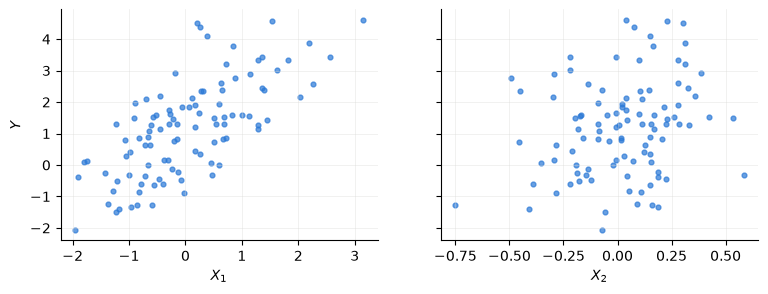

In [2]:
alpha_true, sigma_true = 1, 1
beta_true = [1, 2.5]
size = 100

X1 = rng.normal(size=size)
X2 = rng.normal(size=size) * 0.2
Y = alpha_true + beta_true[0] * X1 + beta_true[1] * X2 + rng.normal(size=size) * sigma_true

fig, axes = plt.subplots(1, 2, sharey=True, figsize=(9, 3))
axes[0].scatter(X1, Y, s=12, alpha=0.7)
axes[1].scatter(X2, Y, s=12, alpha=0.7)
axes[0].set(xlabel="$X_1$", ylabel="$Y$")
axes[1].set(xlabel="$X_2$")
plt.show()

Model bayesowski wymaga określenia rozkładów a priori nieznanych parametrów. Przyjmijmy rozkłady **słabo informacyjne** — szerokie w porównaniu ze spodziewaną skalą parametrów:

$$
\alpha \sim \mathcal{N}(0, 10^2), \qquad \beta_i \sim \mathcal{N}(0, 10^2), \qquad \sigma \sim \mathcal{N}^{+}(0, 1),
$$

gdzie $\mathcal{N}^{+}$ oznacza rozkład półnormalny (*half-normal*, rozkład $|Z|$ dla $Z \sim \mathcal N(0, 1)$) — odchylenie standardowe musi być dodatnie.

W PyMC model definiuje się wewnątrz bloku `with pm.Model()`. Każda zmienna losowa utworzona w tym bloku jest automatycznie dodawana do modelu:

In [3]:
basic_model = pm.Model()

with basic_model:
    # rozkłady a priori nieznanych parametrów
    alpha = pm.Normal("alpha", mu=0, sigma=10)
    beta = pm.Normal("beta", mu=0, sigma=10, shape=2)
    sigma = pm.HalfNormal("sigma", sigma=1)

    # wartość oczekiwana wyniku (zmienna deterministyczna)
    mu = alpha + beta[0] * X1 + beta[1] * X2

    # wiarygodność: rozkład obserwacji przy danych parametrach
    Y_obs = pm.Normal("Y_obs", mu=mu, sigma=sigma, observed=Y)

basic_model

Kilka uwag:

* Pierwszy argument konstruktora rozkładu to **nazwa** zmiennej w modelu — pod tą nazwą znajdziemy jej próbki w wynikach.
* Argument `shape=2` tworzy wektor dwóch niezależnych zmiennych o tym samym rozkładzie.
* `mu` nie jest liczbą, lecz **wyrażeniem symbolicznym** PyTensor zależnym od zmiennych losowych `alpha` i `beta`; PyMC śledzi te zależności.
* Argument `observed` oznacza, że wartości zmiennej `Y_obs` są znane (to nasze dane). Zmienna obserwowana definiuje funkcję wiarygodności.

Strukturę modelu można przedstawić w postaci grafu (w notacji *plate notation*). Owale to zmienne losowe (szare — obserwowane), prostokąty z zaokrąglonymi rogami — zmienne deterministyczne, a prostokąt z liczbą — powtórzenie zmiennych wzdłuż wymiaru o danej długości:

Zmienne swobodne (parametry): [alpha, beta, sigma]
Zmienne obserwowane:          [Y_obs]


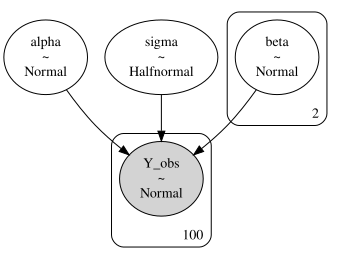

In [4]:
print("Zmienne swobodne (parametry):", basic_model.free_RVs)
print("Zmienne obserwowane:         ", basic_model.observed_RVs)
pm.model_to_graphviz(basic_model)

### 1.3. Rozkłady i wyrażenia symboliczne

Rozkład można utworzyć także poza modelem metodą `.dist()`. Funkcja `pm.draw` losuje wartości z rozkładu lub dowolnego wyrażenia zależnego od zmiennych losowych, a `pm.logp` oblicza logarytm gęstości. Losowanie wyrażenia `mu` z modelu oznacza losowanie z jego rozkładu **a priori** (parametry są losowane z rozkładów a priori):

In [5]:
x = pm.Normal.dist(mu=0, sigma=1)
print("5 losowań z N(0, 1):     ", pm.draw(x, draws=5, random_seed=1).round(3))
print("log N(0,5 | 0, 1):       ", pm.logp(x, 0.5).eval())
print("typ wyrażenia mu:        ", type(mu))
print("mu dla 3 losowań a priori:", pm.draw(mu, draws=3, random_seed=1)[:, :4].round(1), "...")

5 losowań z N(0, 1):      [-0.64   0.393 -0.393  1.097 -2.673]
log N(0,5 | 0, 1):        -1.0439385332046727
typ wyrażenia mu:         <class 'pytensor.tensor.variable.TensorVariable'>
mu dla 3 losowań a priori: [[ 28.4  23.3  37.7  15.6]
 [  9.9  10.1  20.6   4.8]
 [ 13.  -18.9  36.  -49.1]] ...


### 1.4. Kontrola predykcyjna a priori

Zanim dopasujemy model, warto sprawdzić, jakie dane model „uważa” za możliwe **przed** zobaczeniem danych. Funkcja `pm.sample_prior_predictive` losuje parametry z rozkładów a priori, a następnie dane z rozkładu wiarygodności. Jeżeli wygenerowane dane są zupełnie nierealistyczne, rozkłady a priori należy poprawić.

Sampling: [Y_obs, alpha, beta, sigma]


Zakres danych z rozkładu a priori (1%–99%): [-37.4  35.7]
Zakres obserwacji:                          [-1.5  4.6]


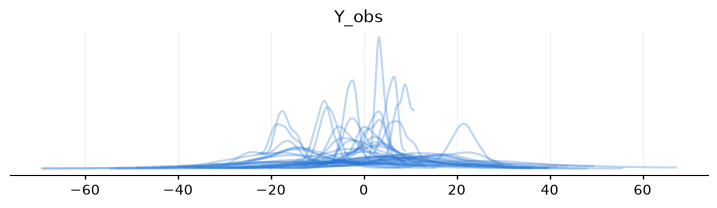

In [6]:
with basic_model:
    prior = pm.sample_prior_predictive(draws=500, random_seed=RANDOM_SEED)

prior_y = prior.prior_predictive["Y_obs"]
print("Zakres danych z rozkładu a priori (1%–99%):", np.quantile(prior_y, [0.01, 0.99]).round(1))
print("Zakres obserwacji:                         ", np.quantile(Y, [0.01, 0.99]).round(1))
az.plot_ppc_dist(prior, group="prior_predictive");

Rozkład a priori dopuszcza wartości $Y$ rzędu kilkudziesięciu, a więc znacznie szersze niż obserwowane — tak powinno być w przypadku rozkładów słabo informacyjnych: nie wykluczają one realistycznych wartości, a jednocześnie nie są absurdalnie szerokie (np. $\pm 10^6$).

### 1.5. Próbkowanie z rozkładu a posteriori

Wnioskowanie uruchamia funkcja `pm.sample`. Domyślnie PyMC wybiera algorytm NUTS dla parametrów ciągłych i uruchamia kilka (zwykle 4) niezależnych **łańcuchów**, każdy z 1000 krokami **adaptacji** (*tuning* — dobór długości kroku i macierzy mas; te próbki są odrzucane) i 1000 próbkami właściwymi.

Parametr `random_seed` zapewnia powtarzalność wyników, a `progressbar=False` wyłącza pasek postępu (podczas pracy możesz go usunąć, aby widzieć postęp próbkowania).

In [7]:
with basic_model:
    idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


Wynikiem jest obiekt `DataTree` (z biblioteki `xarray`; w starszych wersjach ArviZ — `InferenceData`) podzielony na **grupy**: `posterior` (próbki parametrów), `sample_stats` (statystyki próbnika, m.in. informacje o rozbieżnościach), `observed_data` (dane). Każda zmienna to wielowymiarowa tablica z nazwanymi wymiarami `chain` i `draw` (oraz ewentualnie własnymi wymiarami zmiennej):

In [8]:
print(list(idata.children))
idata.posterior

['posterior', 'sample_stats', 'observed_data']


<xarray.DataTree 'posterior'>
Group: /posterior
    Dimensions:     (chain: 4, draw: 1000, beta_dim_0: 2)
    Coordinates:
      * chain       (chain) int64 32B 0 1 2 3
      * draw        (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
      * beta_dim_0  (beta_dim_0) int64 16B 0 1
    Data variables:
        alpha       (chain, draw) float64 32kB 1.191 0.8997 0.8957 ... 1.105 1.121
        beta        (chain, draw, beta_dim_0) float64 64kB 0.9645 1.717 ... 1.892
        sigma       (chain, draw) float64 32kB 1.111 0.9394 1.153 ... 1.047 0.9624
    Attributes:
        created_at:                 2026-11-13T20:00:09.846045+00:00
        creation_library:           ArviZ
        creation_library_version:   1.3.1
        creation_library_language:  Python
        inference_library:          pymc
        inference_library_version:  6.4.0
        sample_dims:                ['chain', 'draw']
        sampling_time:              0.8559982776641846
        tuning_steps:               1000

In [9]:
# Próbki można przetwarzać jak zwykłe tablice xarray/numpy
beta_samples = idata.posterior["beta"]
print("Kształt próbek beta:", beta_samples.shape)
print("Średnie a posteriori beta:", beta_samples.mean(dim=("chain", "draw")).values.round(3))
print("P(beta_2 > 2 | dane) ≈", float((beta_samples[..., 1] > 2).mean()))

Kształt próbek beta: (4, 1000, 2)
Średnie a posteriori beta: [1.069 2.012]
P(beta_2 > 2 | dane) ≈ 0.51075


### 1.6. Podsumowanie wyników i diagnostyka zbieżności

Funkcja `az.summary` zwraca tabelę z podstawowymi statystykami rozkładu a posteriori i diagnostykami:

* `mean`, `sd` — średnia i odchylenie standardowe rozkładu a posteriori,
* `eti89_lb`, `eti89_ub` — granice **89-procentowego przedziału wiarygodności** o równych ogonach (*equal-tailed interval*; domyślny poziom 89% w ArviZ 1.x celowo nie jest „magicznym” 95%),
* `ess_bulk`, `ess_tail` — **efektywna liczba próbek** (*effective sample size*): próbki MCMC są skorelowane, więc niosą mniej informacji niż tyle samo próbek niezależnych; `ess_tail` dotyczy ogonów rozkładu (ważne przy przedziałach),
* `r_hat` — statystyka $\hat{R}$ porównująca zmienność wewnątrz łańcuchów i między nimi; wartości $> 1{,}01$ sygnalizują brak zbieżności,
* `mcse_mean`, `mcse_sd` — błąd Monte Carlo oszacowania średniej i odchylenia standardowego.

Dla rozkładu a posteriori przedział wiarygodności ma bezpośrednią interpretację: *przy przyjętym modelu i danych parametr leży w przedziale z prawdopodobieństwem 89%*.

In [10]:
az.summary(idata)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,1.103,0.103,0.93,1.3,6865,2981,1.00,0.0012,0.0016
beta[0],1.069,0.1,0.91,1.2,6125,3664,1.00,0.0013,0.0015
beta[1],2.01,0.43,1.3,2.7,5947,3614,1.00,0.0056,0.0066
sigma,1.012,0.075,0.9,1.1,6148,3324,1.00,0.00095,0.0012


Wykres śladów (*trace plot*) pokazuje po lewej oszacowania gęstości rozkładów a posteriori (osobno dla każdego łańcucha), a po prawej wartości kolejnych próbek. Dobrze wymieszane łańcuchy wyglądają jak „włochata gąsienica”, a gęstości z różnych łańcuchów pokrywają się.

Ważną diagnostyką NUTS są **rozbieżności** (*divergences*): sygnalizują, że próbnik nie był w stanie dokładnie zbadać pewnego obszaru rozkładu a posteriori (np. o bardzo zmiennej krzywiźnie). Nawet kilka rozbieżności oznacza, że wynikom nie można w pełni ufać.

rozbieżności: 0, maks. R-hat: 1.002, min. ESS (bulk): 5947


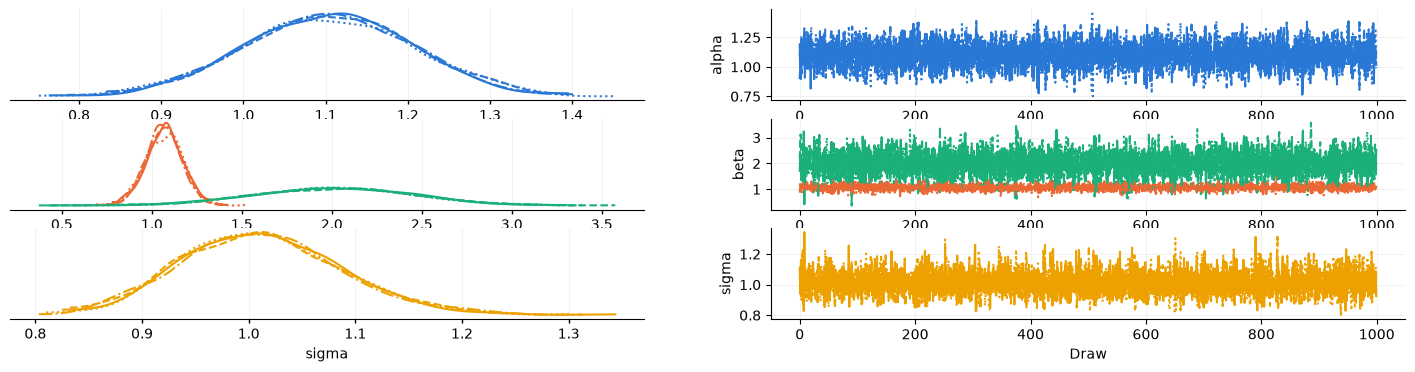

In [11]:
az.plot_trace_dist(idata);


def check(idata):
    # Krótkie podsumowanie diagnostyk: liczba rozbieżności, największe R-hat, najmniejsze ESS
    diag = az.summary(idata, kind="diagnostics")
    print(f"rozbieżności: {int(idata.sample_stats['diverging'].sum())}, "
          f"maks. R-hat: {diag['r_hat'].max():.3f}, min. ESS (bulk): {diag['ess_bulk'].min():.0f}")


check(idata)

❓ **Pytanie 1.** Porównaj oszacowania z prawdziwymi wartościami parametrów. Czy prawdziwe wartości leżą w przedziałach 89%? Dlaczego $\beta_2$ jest oszacowane z dużo większą niepewnością niż $\beta_1$, choć obie zmienne mają w modelu taki sam rozkład a priori? (Wskazówka: porównaj rozrzut $X_1$ i $X_2$.)

### 1.7. Estymator MAP

Jeżeli potrzebujemy tylko oszacowania punktowego, możemy znaleźć **maksimum a posteriori** (MAP) metodami optymalizacji. Jest to szybkie, ale nie daje informacji o niepewności, a dla rozkładów skośnych lub wielomodalnych może być mylące. Zwróć uwagę na zmienną `sigma_log__`: PyMC przekształca parametry o ograniczonym zakresie (tu $\sigma > 0$) do nieograniczonej przestrzeni, w której działa próbnik.

In [12]:
map_estimate = pm.find_MAP(model=basic_model, progressbar=False)
map_estimate

{'alpha': array(1.10351265),
 'beta': array([1.06662836, 2.00208578]),
 'sigma_log__': array(-0.01524606),
 'sigma': array(0.98486957)}

### 1.8. Kontrola predykcyjna a posteriori

Dopasowany model powinien generować dane podobne do zaobserwowanych. Funkcja `pm.sample_posterior_predictive` losuje dla każdej próbki parametrów nowy zbiór danych z rozkładu wiarygodności. Parametr `extend_inferencedata=True` dodaje wyniki do obiektu `idata` (grupa `posterior_predictive`).

Sampling: [Y_obs]


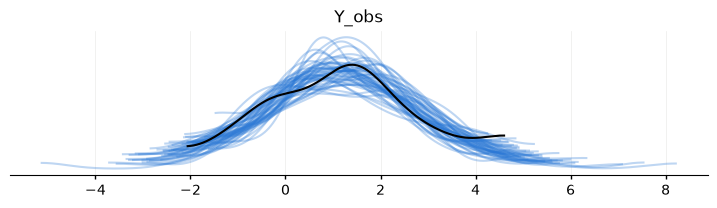

In [13]:
with basic_model:
    pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=RANDOM_SEED, progressbar=False)

az.plot_ppc_dist(idata);

### 1.9. Współrzędne, wymiary i dane zmienne — predykcja dla nowych obserwacji

W praktyce wygodnie jest:

* nadawać wymiarom zmiennych **nazwy i współrzędne** (`coords`, `dims`) — wyniki są wtedy czytelnie opisane, a wymiary nie muszą być podawane liczbowo,
* przekazywać dane przez kontener **`pm.Data`** — można je później podmienić funkcją `pm.set_data`, np. aby wykonać predykcję dla nowych wartości zmiennych objaśniających,
* nazywać ważne wielkości pośrednie za pomocą **`pm.Deterministic`** — ich wartości są zapisywane w wynikach.

Przepiszmy model regresji w tym stylu:

In [14]:
coords = {"predictor": ["X1", "X2"], "obs_id": np.arange(size)}

with pm.Model(coords=coords) as regression:
    X_data = pm.Data("X", np.column_stack([X1, X2]), dims=("obs_id", "predictor"))

    alpha = pm.Normal("alpha", mu=0, sigma=10)
    beta = pm.Normal("beta", mu=0, sigma=10, dims="predictor")
    sigma = pm.HalfNormal("sigma", sigma=1)

    mu = pm.Deterministic("mu", alpha + X_data @ beta, dims="obs_id")
    pm.Normal("Y_obs", mu=mu, sigma=sigma, observed=Y, dims="obs_id")

    idata_reg = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

az.summary(idata_reg, var_names=["alpha", "beta", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [alpha, beta, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
alpha,1.102,0.103,0.93,1.3,6526,3135,1.00,0.0013,0.0016
beta[X1],1.07,0.1,0.91,1.2,5202,3437,1.00,0.0014,0.0015
beta[X2],2.01,0.43,1.3,2.7,5998,3507,1.00,0.0056,0.0061
sigma,1.013,0.074,0.9,1.1,6209,3432,1.00,0.00093,0.0012


Teraz podmieniamy dane na nową siatkę wartości $X_1$ (przy $X_2 = 0$) i wraz z danymi zmieniamy współrzędne wymiaru `obs_id`. Opcja `predictions=True` zapisuje wynik w osobnej grupie `predictions`. Losujemy dwie wielkości:

* `mu` — wartość oczekiwaną $Y$ (jej niepewność wynika tylko z niepewności parametrów),
* `Y_obs` — nową obserwację (dochodzi do tego losowy szum o odchyleniu $\sigma$).

Sampling: [Y_obs]


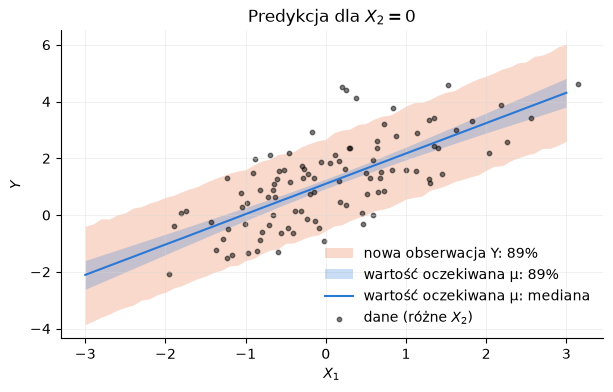

In [15]:
x1_new = np.linspace(-3, 3, 61)
X_new = np.column_stack([x1_new, np.zeros_like(x1_new)])

with regression:
    pm.set_data({"X": X_new}, coords={"obs_id": np.arange(len(x1_new))})
    pred = pm.sample_posterior_predictive(idata_reg, var_names=["mu", "Y_obs"], predictions=True,
                                          random_seed=RANDOM_SEED, progressbar=False)


def plot_band(ax, x, draws, color="C0", label=None, prob=0.89, line=True):
    # Mediana i centralny przedział `prob` próbek (redukujemy wymiary chain i draw)
    q = draws.quantile([(1 - prob) / 2, 0.5, (1 + prob) / 2], dim=("chain", "draw")).values
    ax.fill_between(x, q[0], q[2], color=color, alpha=0.25, lw=0,
                    label=None if label is None else f"{label}: {prob:.0%}")
    if line:
        ax.plot(x, q[1], color=color, lw=1.5, label=None if label is None else f"{label}: mediana")


fig, ax = plt.subplots(figsize=(7, 4))
plot_band(ax, x1_new, pred.predictions["Y_obs"], color="C1", label="nowa obserwacja Y", line=False)
plot_band(ax, x1_new, pred.predictions["mu"], color="C0", label="wartość oczekiwana μ")
ax.scatter(X1, Y, s=10, color="k", alpha=0.5, label="dane (różne $X_2$)")
ax.set(xlabel="$X_1$", ylabel="$Y$", title="Predykcja dla $X_2 = 0$")
ax.legend()
plt.show()

❓ **Pytanie 2.** Dlaczego pasmo dla nowej obserwacji $Y$ jest znacznie szersze niż pasmo dla wartości oczekiwanej $\mu$? Którego pasma użyjesz, prognozując wynik pojedynczego nowego pomiaru, a którego — opisując średnią zależność $Y$ od $X_1$? Jak zmieniłaby się szerokość obu pasm, gdybyśmy mieli 10 000 obserwacji zamiast 100?

## 2. Nadmiarowe zgony — problem i dane

### 2.1. Czym są zgony nadmiarowe?

Liczba zgonów przypisanych COVID-19 w oficjalnych statystykach zależy od liczby wykonywanych testów, sposobu wypełniania kart zgonu i wydolności systemu raportowania, dlatego trudno ją porównywać między krajami. Odporniejszą miarą skutków pandemii są **zgony nadmiarowe** (*excess deaths*):

$$
\text{zgony nadmiarowe}_t = \text{zgony zaobserwowane}_t - \text{zgony oczekiwane}_t,
$$

gdzie **zgony oczekiwane** to liczba zgonów, której należałoby się spodziewać, **gdyby pandemii nie było**. Jest to wielkość **kontrfaktyczna** (*counterfactual*) — nigdy jej nie obserwujemy, musimy ją oszacować modelem dopasowanym do danych sprzed pandemii (u nas: lata 2015–2019) i przedłużonym na kolejne lata. Do porównań między krajami o różnej liczbie ludności używa się **wskaźnika P** (*P-score*):

$$
P = 100\% \cdot \frac{\text{zaobserwowane} - \text{oczekiwane}}{\text{oczekiwane}}.
$$

Podejście bayesowskie daje nie tylko oszacowanie punktowe, ale cały rozkład a posteriori liczby zgonów oczekiwanych, a więc i przedziały wiarygodności dla liczby zgonów nadmiarowych.

Zgony nadmiarowe obejmują zarówno zgony bezpośrednio spowodowane przez COVID-19 (także niezdiagnozowane), jak i skutki pośrednie: przeciążenie szpitali, odkładanie diagnostyki i leczenia innych chorób. Mogą je też pomniejszać efekty przeciwne, np. mniejsza liczba wypadków drogowych czy zachorowań na grypę w okresach ograniczeń.

### 2.2. Czynniki mogące wpływać na liczbę zgonów nadmiarowych

Przykłady czynników, które mogą tłumaczyć różnice między krajami i okresami:

| Czynnik | Możliwy mechanizm |
|---|---|
| intensywność epidemii (fale zakażeń, warianty wirusa) | bezpośrednia przyczyna zgonów; np. wariant Delta jesienią 2021 r. |
| struktura wieku ludności | ryzyko zgonu z powodu COVID-19 rośnie bardzo szybko z wiekiem |
| odsetek osób zaszczepionych | szczepienia (od 2021 r.) silnie zmniejszały ryzyko ciężkiego przebiegu |
| stan zdrowia populacji | choroby układu krążenia, cukrzyca i otyłość zwiększają ryzyko ciężkiego przebiegu |
| wydolność systemu ochrony zdrowia | przeciążenie szpitali zwiększa śmiertelność, także z innych przyczyn |
| zamożność kraju (PKB na mieszkańca) | wpływa pośrednio na prawie wszystkie powyższe czynniki |
| ograniczenia epidemiczne (*lockdown*, maseczki, zamknięcie szkół) | zmniejszają transmisję wirusa, ale mogą utrudniać dostęp do leczenia |
| zaufanie do instytucji, zachowania społeczne | wpływają na skłonność do szczepień i przestrzegania zaleceń |
| zdarzenia niezwiązane z COVID-19 | fale upałów (np. lato 2022), sezony grypowe, wojny i migracje (np. napływ uchodźców z Ukrainy w 2022 r. zmienia liczbę ludności) |
| efekt „przyspieszonych zgonów” (*mortality displacement*) | jeżeli epidemia zabiera głównie osoby najbardziej schorowane, w kolejnych latach zgonów może być mniej, niż wynikałoby z trendu |
| jakość danych | opóźnienia w rejestracji zgonów, niepełna rejestracja w części krajów |

Część z tych czynników uwzględnimy bezpośrednio w modelach (sezonowość, długość miesiąca, trend związany ze starzeniem się ludności), a kilka zmiennych opisujących kraje (szczepienia, struktura wieku, PKB, liczba łóżek szpitalnych) zbadamy w rozdziale 6.

### 2.3. Dane do zajęć

Wszystkie dane potrzebne w instrukcji i w zadaniach znajdują się w katalogu `data/`. Są to kopie lub wyciągi publicznie dostępnych zbiorów, pobrane 13 listopada 2026 r. skryptem `prepare_data.py` (Dodatek B). Zbiory źródłowe są aktualizowane, poprawiane, a niektóre archiwizowane, dlatego na zajęciach korzystamy wyłącznie z dostarczonych kopii — dzięki temu wyniki są powtarzalne i zgodne z instrukcją.

| Plik | Zawartość | Źródło | Licencja |
|---|---|---|---|
| `world_mortality.csv` | tygodniowe lub miesięczne liczby zgonów ze wszystkich przyczyn w 128 krajach i terytoriach, 2015–2024 | [World Mortality Dataset](https://github.com/akarlinsky/world_mortality) (A. Karlinsky, D. Kobak), wersja z 26.10.2026; plik bez zmian | MIT |
| `country_covariates.csv` | zmienne opisujące kraje: ludność, struktura wieku, PKB, szczepienia, zgłoszone zgony z powodu COVID-19 itd. | wyciąg ze zbioru [COVID-19 dataset Our World in Data](https://github.com/owid/covid-19-data) (stan z 19.08.2024 — ostatniej aktualizacji zarchiwizowanego repozytorium); wartości na wybrane daty i średnie obliczone przy przygotowaniu instrukcji | CC BY 4.0 dla danych OWID; zmienne pochodzące od innych instytucji (ONZ, Bank Światowy, WHO, Oxford COVID-19 Government Response Tracker i in.) — na warunkach tych instytucji |
| `poland_temperature.csv` | miesięczna średnia temperatura i liczba dni upalnych w 10 dużych miastach Polski, 2015–2024 | [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api) (reanalizy ERA5 i ERA5-Land, Copernicus Climate Change Service); dane dobowe zagregowane do miesięcy przy przygotowaniu instrukcji | CC BY 4.0 (*Weather data by Open-Meteo.com*) |

Szczegółowy opis kolumn plików `country_covariates.csv` i `poland_temperature.csv` znajduje się w Dodatku A. Pierwszy z nich wykorzystujemy od rozdziału 4, drugi — w zadaniu 1.

**World Mortality Dataset** (Karlinsky, Kobak, *eLife* 2021) zawiera liczby zgonów ze wszystkich przyczyn (*all-cause mortality*), zebrane z bazy *Short-Term Mortality Fluctuations* projektu Human Mortality Database, z Eurostatu oraz z krajowych urzędów statystycznych i agencji rządowych. Dane są **tygodniowe** (w większości tygodnie ISO 8601: od poniedziałku do niedzieli) lub **miesięczne**, zależnie od kraju. Autorzy zbioru zwracają uwagę, że najnowsze wartości dla każdego kraju są wstępne i mogą być później korygowane, a w części krajów rejestracja zgonów jest niepełna lub opóźniona (np. dane z rejestru cywilnego Brazylii są zaniżone, a dane dla Peru kończą się w październiku 2022 r. z powodu niepełnej rejestracji).

| Kolumna | Znaczenie |
|---|---|
| `iso3c` | trzyliterowy kod kraju (ISO 3166-1 alfa-3) |
| `country_name` | nazwa kraju |
| `year` | rok |
| `time` | numer tygodnia (1–53) lub miesiąca (1–12) |
| `time_unit` | `weekly` lub `monthly` |
| `deaths` | liczba zgonów |

In [16]:
DATA = Path("data")   # pliki dostarczone razem z instrukcją

wmd = pd.read_csv(DATA / "world_mortality.csv")
wmd = wmd[wmd["year"] >= 2015]   # pomijamy kilka błędnych rekordów z rokiem 0
cov = pd.read_csv(DATA / "country_covariates.csv").set_index("iso3c")   # zmienne opisujące kraje (od rozdz. 4)

print("Liczba krajów:", wmd["iso3c"].nunique())
print(wmd.groupby("time_unit")["iso3c"].nunique().rename("liczba krajów"))
wmd.head()

Liczba krajów: 128
time_unit
monthly    76
weekly     52
Name: liczba krajów, dtype: int64


,iso3c,country_name,year,time,time_unit,deaths
0,ALB,Albania,2015,1,monthly,2490.0
1,ALB,Albania,2015,2,monthly,2139.0
2,ALB,Albania,2015,3,monthly,2051.0
3,ALB,Albania,2015,4,monthly,1906.0
4,ALB,Albania,2015,5,monthly,1709.0


### 2.4. Ujednolicenie danych: zgony miesięczne

Aby wszystkie kraje analizować tak samo, przeliczymy dane tygodniowe na miesięczne. Tydzień ISO zaczyna się w poniedziałek i może obejmować dni z dwóch miesięcy, dlatego zgony z każdego tygodnia rozkładamy równomiernie na jego 7 dni, a następnie sumujemy po miesiącach kalendarzowych. Odrzucamy miesiące, które nie są w całości pokryte danymi (na początku i końcu szeregu). Jest to przybliżenie, ale błąd jest niewielki w porównaniu z naturalną zmiennością liczby zgonów.

In [17]:
def to_monthly(wmd):
    weekly = wmd[wmd["time_unit"] == "weekly"]
    # poniedziałek danego tygodnia ISO
    monday = pd.to_datetime(weekly["year"].astype(str) + "-W" + weekly["time"].astype(str).str.zfill(2) + "-1",
                            format="%G-W%V-%u")
    daily = pd.DataFrame({
        "iso3c": np.repeat(weekly["iso3c"].to_numpy(), 7),
        "date": np.repeat(monday.to_numpy(), 7) + np.tile(pd.to_timedelta(np.arange(7), "D"), len(weekly)),
        "deaths": np.repeat(weekly["deaths"].to_numpy() / 7, 7),
    })
    daily["month"] = daily["date"].dt.to_period("M")
    from_weekly = daily.groupby(["iso3c", "month"]).agg(deaths=("deaths", "sum"), n_days=("deaths", "size"))
    from_weekly = from_weekly.reset_index()
    from_weekly = from_weekly[from_weekly["n_days"] == from_weekly["month"].dt.days_in_month]

    monthly = wmd[wmd["time_unit"] == "monthly"].copy()
    monthly["month"] = pd.PeriodIndex.from_fields(year=monthly["year"], month=monthly["time"], freq="M")

    out = pd.concat([from_weekly[["iso3c", "month", "deaths"]], monthly[["iso3c", "month", "deaths"]]])
    out["deaths"] = out["deaths"].round().astype(int)
    out["date"] = out["month"].dt.to_timestamp()
    names = wmd.groupby("iso3c")["country_name"].first()
    out["country"] = out["iso3c"].map(names)
    return out[["iso3c", "country", "date", "deaths"]].sort_values(["iso3c", "date"]).reset_index(drop=True)


monthly = to_monthly(wmd)
print(monthly.shape)
monthly[monthly["iso3c"] == "POL"].tail()

(14190, 4)


,iso3c,country,date,deaths
10886,POL,Poland,2024-07-01,31933
10887,POL,Poland,2024-08-01,32690
10888,POL,Poland,2024-09-01,32145
10889,POL,Poland,2024-10-01,35526
10890,POL,Poland,2024-11-01,33415


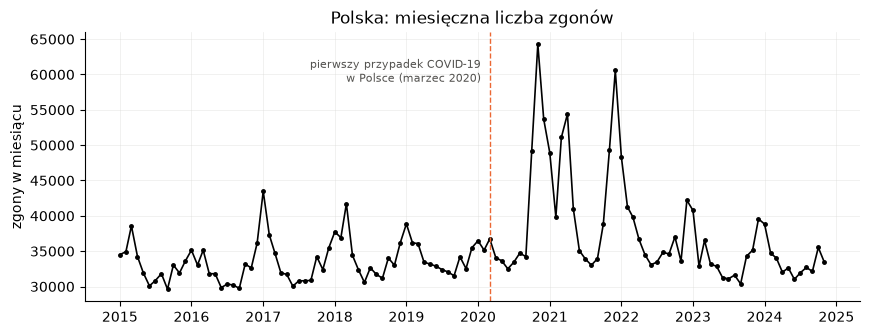

date,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
zgony,395080,389035,403802,412551,408803,478138,519877,449350,409471,368966
liczba miesięcy,12,12,12,12,12,12,12,12,12,11


In [18]:
pol = monthly[monthly["iso3c"] == "POL"].set_index("date")["deaths"]

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(pol.index, pol, color="k", lw=1.2, marker="o", ms=2.5)
ax.axvline(pd.Timestamp("2020-03-01"), color="C1", ls="--", lw=1)
ax.text(pd.Timestamp("2020-01-15"), pol.max() * 0.97, "pierwszy przypadek COVID-19\nw Polsce (marzec 2020)",
        fontsize=8, color="#52514e", va="top", ha="right")
ax.set(ylabel="zgony w miesiącu", title="Polska: miesięczna liczba zgonów")
plt.show()

pol.groupby(pol.index.year).agg(["sum", "count"]).rename(columns={"sum": "zgony", "count": "liczba miesięcy"}).T

Porównajmy kilka krajów. Aby uniezależnić się od liczby ludności, dzielimy liczbę zgonów przez średnią miesięczną z lat 2015–2019 (wartość 1 oznacza poziom typowy sprzed pandemii).

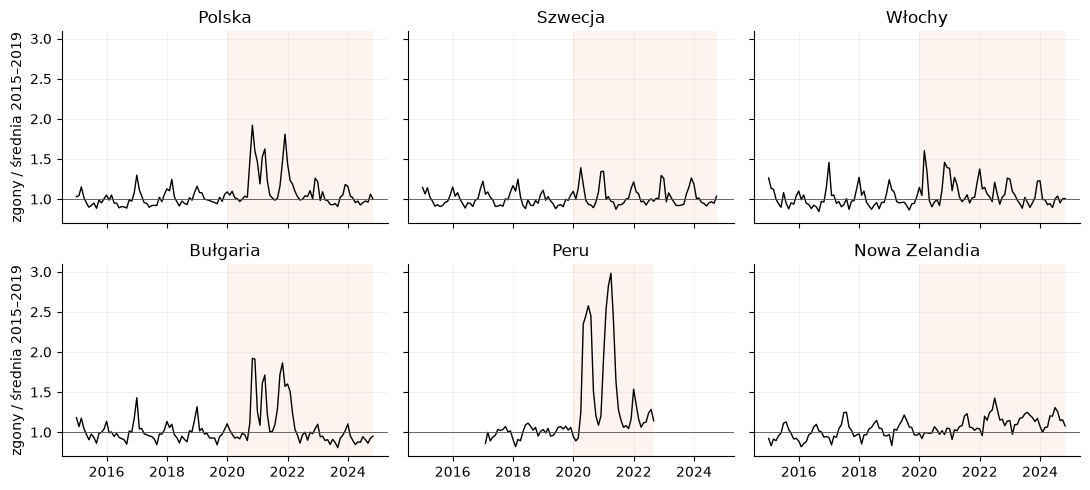

In [19]:
examples = {"POL": "Polska", "SWE": "Szwecja", "ITA": "Włochy", "BGR": "Bułgaria", "PER": "Peru", "NZL": "Nowa Zelandia"}
fig, axes = plt.subplots(2, 3, figsize=(11, 5), sharey=True, sharex=True)
for ax, (iso, name) in zip(axes.flat, examples.items()):
    s = monthly[monthly["iso3c"] == iso].set_index("date")["deaths"]
    ax.plot(s.index, s / s[s.index < "2020"].mean(), color="k", lw=1)
    ax.axhline(1, color="#52514e", lw=0.6)
    ax.axvspan(pd.Timestamp("2020-01-01"), s.index.max(), color="C1", alpha=0.08, lw=0)
    ax.set_title(name)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
for ax in axes[:, 0]:
    ax.set_ylabel("zgony / średnia 2015–2019")
fig.tight_layout()
plt.show()

❓ **Pytanie 3.** W których miesiącach w Polsce umiera najwięcej, a w których najmniej osób? Czy przed 2020 r. widać trend? Kiedy wystąpiły kolejne fale pandemii? Czym różni się sezonowość w Nowej Zelandii od sezonowości w krajach europejskich i dlaczego? Co może oznaczać brak zimowego wzrostu liczby zgonów w Nowej Zelandii w 2020 r.?

*Wskazówka.* Wykresy pozwalają postawić hipotezy, ale odpowiedzi warto potwierdzić obliczeniami w bibliotece pandas — na szeregu `pol` lub (dla innych krajów) na ramce `monthly`:

* średnią liczbę zgonów w poszczególnych miesiącach kalendarzowych obliczysz, grupując według numeru miesiąca, np. `s.groupby(s.index.month).mean()` dla `s = pol[pol.index < "2020"]`; miesiąc z największą wartością wskaże metoda `idxmax`,
* sumy roczne — przez `s.groupby(s.index.year).sum()` lub `s.resample("YS").sum()`,
* miesiące z największą liczbą zgonów w czasie pandemii — metodą `nlargest`, np. `pol["2020":"2022"].nlargest(8)`,
* dla Nowej Zelandii porównaj liczbę zgonów w miesiącach zimowych 2020 r. ze średnią z tych samych miesięcy w latach 2015–2019 (iloraz); dokładniejszy obraz dają dane tygodniowe z ramki `wmd`.

## 3. Model zgonów w Polsce — od prostego do złożonego

Zbudujemy kolejno kilka modeli miesięcznej liczby zgonów, za każdym razem dodając jeden element. Modele dopasowujemy wyłącznie do danych z **okresu referencyjnego 2015–2019**; dane z lat 2020–2023 posłużą w rozdziale 4 do oszacowania zgonów nadmiarowych.

| Model | Wartość oczekiwana | Rozkład obserwacji |
|---|---|---|
| M0 | stała | normalny |
| M1 | stała + efekt miesiąca (sezonowość) | normalny |
| M2 | stała + efekt miesiąca + trend liniowy | normalny |
| M3 | jak M2, ale w skali logarytmicznej i z uwzględnieniem długości miesiąca | Poissona |
| M4 | jak M3 | ujemny dwumianowy |

Przygotujmy dane. Czas $t$ mierzymy w latach od połowy okresu referencyjnego (1 lipca 2017 r.) — dzięki wyśrodkowaniu wyraz wolny oznacza poziom w środku okresu uczącego, a jego oszacowanie jest słabo skorelowane z oszacowaniem trendu.

In [20]:
MONTHS = ["sty", "lut", "mar", "kwi", "maj", "cze", "lip", "sie", "wrz", "paź", "lis", "gru"]
T0 = pd.Timestamp("2017-07-01")


def add_features(df):
    df = df.copy()
    df["month"] = df["date"].dt.month - 1                  # indeks miesiąca 0..11
    df["year"] = df["date"].dt.year
    df["t"] = (df["date"] - T0).dt.days / 365.25          # czas w latach
    df["days"] = df["date"].dt.days_in_month              # liczba dni w miesiącu
    return df


pl = add_features(monthly[monthly["iso3c"] == "POL"]).set_index("date", drop=False)
pre = pl[pl["date"] < "2020-01-01"]                                   # okres referencyjny 2015–2019
post = pl[(pl["date"] >= "2020-01-01") & (pl["date"] < "2024-01-01")]  # okres analizy 2020–2023
print(len(pre), "miesięcy w okresie referencyjnym,", len(post), "w okresie analizy")
pre.head()

60 miesięcy w okresie referencyjnym, 48 w okresie analizy


,iso3c,country,date,deaths,month,year,t,days
date,,,,,,,,
2015-01-01,POL,Poland,2015-01-01,34501,0,2015,-2.496920,31
2015-02-01,POL,Poland,2015-02-01,34934,1,2015,-2.412047,28
2015-03-01,POL,Poland,2015-03-01,38573,2,2015,-2.335387,31
2015-04-01,POL,Poland,2015-04-01,34236,3,2015,-2.250513,30
2015-05-01,POL,Poland,2015-05-01,31914,4,2015,-2.168378,31


Wszystkie modele będą miały tę samą strukturę danych: zmienne objaśniające i obserwacje przekazujemy przez `pm.Data`, aby później móc podmienić je na dane z lat 2020–2023. Do dopasowania używamy wspólnej funkcji, która kolejno: losuje z rozkładu predykcyjnego a priori, próbkuje z rozkładu a posteriori, losuje z rozkładu predykcyjnego a posteriori i oblicza logarytmy wiarygodności poszczególnych obserwacji (potrzebne do porównania modeli w p. 3.6).

In [21]:
def data_containers(df):
    # Rejestruje dane w bieżącym modelu; zwraca (indeks miesiąca, czas, liczba dni, zgony)
    return (pm.Data("month_idx", df["month"].to_numpy(), dims="date"),
            pm.Data("t", df["t"].to_numpy(), dims="date"),
            pm.Data("days", df["days"].to_numpy(), dims="date"),
            pm.Data("deaths_obs", df["deaths"].to_numpy(), dims="date"))


def fit(model):
    with model:
        idata = pm.sample_prior_predictive(random_seed=RANDOM_SEED)
        idata.update(pm.sample(random_seed=RANDOM_SEED, progressbar=False))
        pm.sample_posterior_predictive(idata, extend_inferencedata=True, random_seed=RANDOM_SEED, progressbar=False)
        pm.compute_log_likelihood(idata, progressbar=False)
    check(idata)
    return idata


def coverage(idata, prob=0.89):
    # Odsetek obserwacji wewnątrz centralnego przedziału predykcyjnego `prob`
    pp = idata.posterior_predictive["deaths"]
    lo, hi = pp.quantile([(1 - prob) / 2, (1 + prob) / 2], dim=("chain", "draw")).values
    y = idata.observed_data["deaths"].values
    return np.mean((y >= lo) & (y <= hi))


def plot_fit(idata, df, title, group="posterior_predictive"):
    fig, ax = plt.subplots(figsize=(10, 3.2))
    draws = idata[group]["deaths"]
    plot_band(ax, df.index, draws, color="C0", label="rozkład predykcyjny")
    ax.plot(df.index, df["deaths"], "o", color="k", ms=3, label="dane")
    ax.set(ylabel="zgony w miesiącu", title=title)
    ax.legend(loc="upper left", ncols=3, fontsize=8)
    plt.show()


coords = {"date": pre.index, "month": MONTHS}

### 3.1. Model M0: stała średnia

Najprostszy model zakłada, że liczba zgonów w każdym miesiącu pochodzi z tego samego rozkładu normalnego:

$$
\text{zgony}_t \sim \mathcal{N}(\mu, \sigma^2), \qquad \mu \sim \mathcal{N}(30\,000;\ 10\,000^2), \qquad \sigma \sim \mathcal{N}^{+}(0;\ 5\,000^2).
$$

Skąd rozkład a priori dla $\mu$? Polska ma ok. 38 mln mieszkańców, a roczny współczynnik zgonów w krajach europejskich wynosi ok. 1%, czyli spodziewamy się ok. 380 tys. zgonów rocznie, tj. ok. 30 tys. miesięcznie. Odchylenie 10 tys. wyraża dużą niepewność tego zgrubnego oszacowania.

In [22]:
with pm.Model(coords=coords) as m0:
    month, t, days, y = data_containers(pre)
    intercept = pm.Normal("intercept", 30_000, 10_000)
    sigma = pm.HalfNormal("sigma", 5_000)
    pm.Normal("deaths", mu=intercept, sigma=sigma, observed=y, dims="date")

idata0 = fit(m0)
az.summary(idata0, var_names=["intercept", "sigma"])

Sampling: [deaths, intercept, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.002, min. ESS (bulk): 3268


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,3.35e+04,3.76e+02,33000,34000,4057,2942,1.00,5.9,6.4
sigma,2904,271,2500,3400,3268,2452,1.00,4.8,4.9


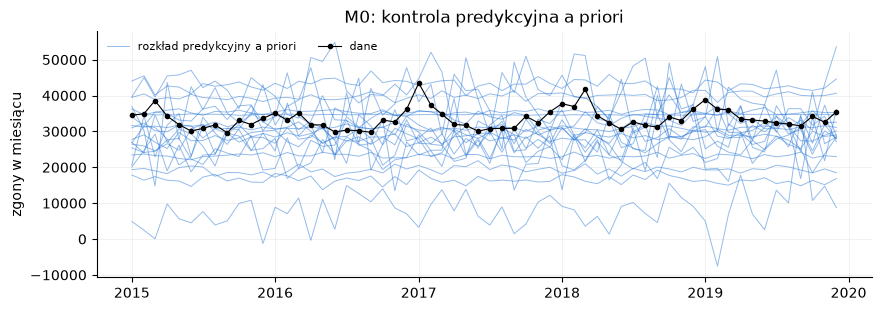

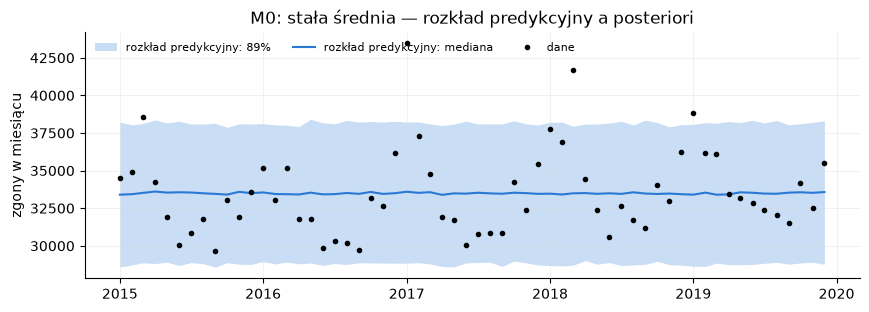

In [23]:
# Kontrola predykcyjna a priori: 20 szeregów czasowych wylosowanych z modelu przed dopasowaniem
fig, ax = plt.subplots(figsize=(10, 3.2))
prior_series = idata0.prior_predictive["deaths"].isel(chain=0)
for d in range(20):
    ax.plot(pre.index, prior_series.isel(draw=d), color="C0", lw=0.7, alpha=0.5,
            label="rozkład predykcyjny a priori" if d == 0 else None)
ax.plot(pre.index, pre["deaths"], "o-", color="k", ms=3, lw=0.8, label="dane")
ax.set(ylabel="zgony w miesiącu", title="M0: kontrola predykcyjna a priori")
ax.legend(loc="upper left", ncols=2, fontsize=8)
plt.show()

plot_fit(idata0, pre, "M0: stała średnia — rozkład predykcyjny a posteriori")

Kontrola predykcyjna a priori pokazuje, że rozkład a priori dopuszcza szeroki, ale realistyczny zakres liczby zgonów (choć przy skrajnych losowaniach także wartości ujemne — rozkład normalny nie „wie”, że zgonów nie może być mniej niż zero). Model po dopasowaniu „zgaduje” średnią, ale pasmo predykcyjne jest bardzo szerokie, a reszty mają wyraźną strukturę: zimą zgonów jest systematycznie więcej, latem — mniej. Rozkład reszt nie jest więc losowym szumem, czego model nie uwzględnia.

### 3.2. Model M1: sezonowość

Dodajemy efekt miesiąca kalendarzowego $\gamma_{m(t)}$, gdzie $m(t) \in \{1, \dots, 12\}$ to miesiąc obserwacji $t$:

$$
\text{zgony}_t \sim \mathcal{N}(\mu_t, \sigma^2), \qquad \mu_t = \alpha + \gamma_{m(t)}, \qquad \sum_{m=1}^{12} \gamma_m = 0.
$$

Bez ograniczenia $\sum_m \gamma_m = 0$ model byłby **nieidentyfikowalny**: dodanie tej samej stałej do wszystkich $\gamma_m$ i odjęcie jej od $\alpha$ nie zmienia $\mu_t$. Rozkład `pm.ZeroSumNormal` to wielowymiarowy rozkład normalny ograniczony do wektorów o sumie zero. Indeksowanie `month_effect[month]` wybiera dla każdej obserwacji efekt jej miesiąca.

Sampling: [deaths, intercept, month_effect, sigma]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, month_effect, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.004, min. ESS (bulk): 4114


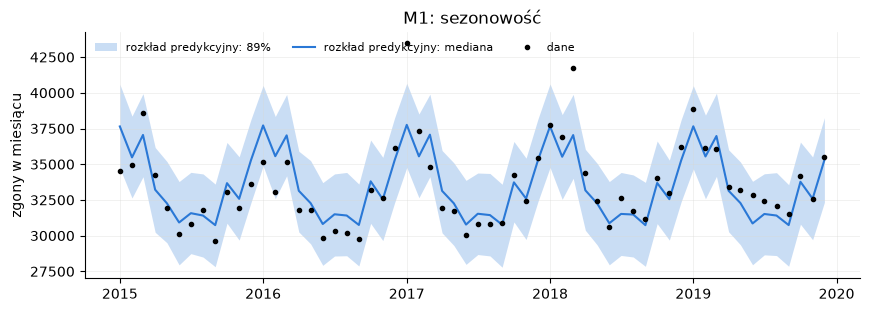

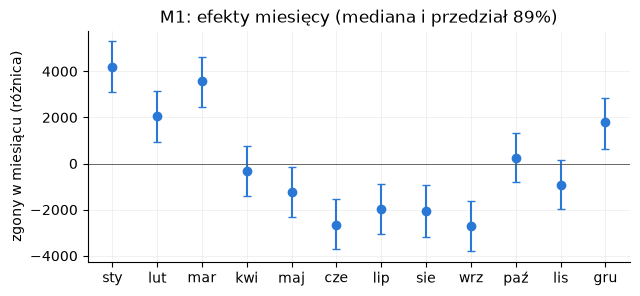

In [24]:
with pm.Model(coords=coords) as m1:
    month, t, days, y = data_containers(pre)
    intercept = pm.Normal("intercept", 30_000, 10_000)
    month_effect = pm.ZeroSumNormal("month_effect", sigma=3_000, dims="month")
    mu = pm.Deterministic("mu", intercept + month_effect[month], dims="date")
    sigma = pm.HalfNormal("sigma", 5_000)
    pm.Normal("deaths", mu=mu, sigma=sigma, observed=y, dims="date")

idata1 = fit(m1)
plot_fit(idata1, pre, "M1: sezonowość")


def plot_month_effects(effect, ylabel, title, ref=0):
    # Mediana i przedział 89% efektu dla każdego miesiąca
    lo, med, hi = effect.quantile([0.055, 0.5, 0.945], dim=("chain", "draw")).values
    fig, ax = plt.subplots(figsize=(7, 3))
    ax.errorbar(np.arange(12), med, yerr=[med - lo, hi - med], fmt="o", color="C0", capsize=3)
    ax.axhline(ref, color="#52514e", lw=0.6)
    ax.set_xticks(np.arange(12), MONTHS)
    ax.set(ylabel=ylabel, title=title)
    plt.show()


plot_month_effects(idata1.posterior["month_effect"], "zgony w miesiącu (różnica)",
                   "M1: efekty miesięcy (mediana i przedział 89%)")

### 3.3. Model M2: trend

Liczba zgonów rośnie z roku na rok, głównie z powodu starzenia się ludności. Dodajemy trend liniowy $\beta t$ (zmiana miesięcznej liczby zgonów na rok):

$$
\mu_t = \alpha + \beta t + \gamma_{m(t)}, \qquad \beta \sim \mathcal{N}(0;\ 1\,000^2).
$$

Sampling: [deaths, intercept, month_effect, sigma, trend]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, trend, month_effect, sigma]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.005, min. ESS (bulk): 4058


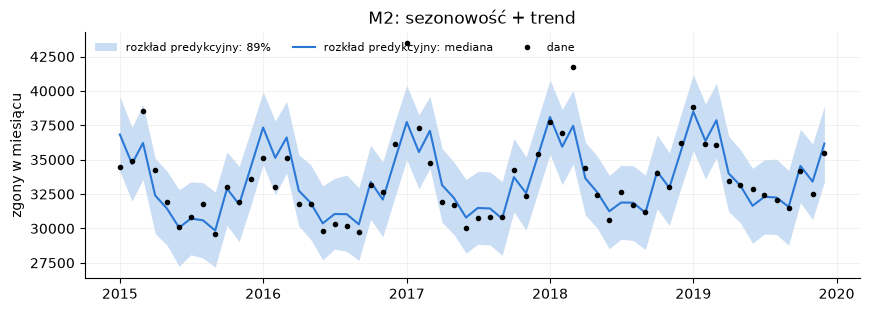

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,33502,199,33000,34000,8457,3172,1.00,2.2,3.4
trend,408,137,190,620,7866,2993,1.00,1.5,2.2
sigma,1531,158,1300,1800,4058,3370,1.00,2.5,2.5


In [25]:
with pm.Model(coords=coords) as m2:
    month, t, days, y = data_containers(pre)
    intercept = pm.Normal("intercept", 30_000, 10_000)
    trend = pm.Normal("trend", 0, 1_000)
    month_effect = pm.ZeroSumNormal("month_effect", sigma=3_000, dims="month")
    mu = pm.Deterministic("mu", intercept + trend * t + month_effect[month], dims="date")
    sigma = pm.HalfNormal("sigma", 5_000)
    pm.Normal("deaths", mu=mu, sigma=sigma, observed=y, dims="date")

idata2 = fit(m2)
plot_fit(idata2, pre, "M2: sezonowość + trend")
az.summary(idata2, var_names=["intercept", "trend", "sigma"])

### 3.4. Model M3: model dla zliczeń (rozkład Poissona)

Modele M0–M2 mają kilka wad:

* liczba zgonów jest **liczbą całkowitą nieujemną**, a rozkład normalny jest ciągły i dopuszcza wartości ujemne (tu praktycznie bez znaczenia, ale ważne dla małych krajów),
* efekty sezonowe i trend działają raczej **multiplikatywnie** (np. zimą umiera o 10% więcej osób niż średnio, a nie o stałą liczbę), co zapisuje się addytywnie w skali logarytmicznej,
* miesiące mają **różną długość** (28–31 dni, czyli różnica do 10%!), więc część „sezonowości” w M1–M2 wynika po prostu z liczby dni.

Model M3 to **uogólniony model liniowy** (GLM) z logarytmiczną funkcją wiążącą i **ekspozycją** (*offset*) równą liczbie dni w miesiącu:

$$
\text{zgony}_t \sim \mathrm{Poisson}(\lambda_t), \qquad \log \lambda_t = \log(\text{dni}_t) + a + b\,t + g_{m(t)}.
$$

Wtedy $e^{a + b t + g_m}$ to średnia **dzienna** liczba zgonów, $e^{b}$ — mnożnik roczny (np. $b = 0{,}01$ oznacza wzrost o ok. 1% rocznie), a $e^{g_m}$ — względny efekt miesiąca. Rozkłady a priori dobieramy w tej skali: ok. 1000 zgonów dziennie, zmiana o kilka procent rocznie, efekty sezonowe rzędu $\pm 20\%$.

Sampling: [deaths, intercept, month_effect, trend]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, trend, month_effect]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.004, min. ESS (bulk): 5589


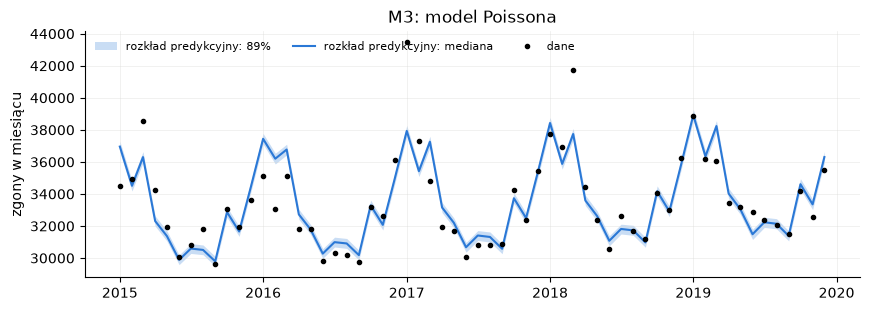

Pokrycie przedziałem predykcyjnym 89%: M2 97%, M3 35%


In [26]:
with pm.Model(coords=coords) as m3:
    month, t, days, y = data_containers(pre)
    intercept = pm.Normal("intercept", np.log(1_000), 0.5)
    trend = pm.Normal("trend", 0, 0.05)
    month_effect = pm.ZeroSumNormal("month_effect", sigma=0.2, dims="month")
    mu = pm.Deterministic("mu", pm.math.exp(np.log(days) + intercept + trend * t + month_effect[month]), dims="date")
    pm.Poisson("deaths", mu=mu, observed=y, dims="date")

idata3 = fit(m3)
plot_fit(idata3, pre, "M3: model Poissona")
print(f"Pokrycie przedziałem predykcyjnym 89%: M2 {coverage(idata2):.0%}, M3 {coverage(idata3):.0%}")

Pasmo predykcyjne modelu Poissona jest bardzo wąskie i większość obserwacji leży poza nim. W rozkładzie Poissona wariancja jest równa średniej, więc przy ok. 33 tys. zgonów miesięcznie odchylenie standardowe wynosi tylko $\sqrt{33\,000} \approx 180$. Tymczasem rzeczywiste wahania z miesiąca na miesiąc (np. z powodu epidemii grypy czy upałów) sięgają 1–2 tys. Mamy do czynienia z **nadmierną dyspersją** (*overdispersion*).

### 3.5. Model M4: rozkład ujemny dwumianowy

Rozkład ujemny dwumianowy $\mathrm{NB}(\mu, \alpha)$ ma wartość oczekiwaną $\mu$ i wariancję $\mu + \mu^2/\alpha$. Wygodniej jest go parametryzować współczynnikiem $c = 1/\sqrt{\alpha}$: dla dużych liczebności odchylenie standardowe wynosi w przybliżeniu $c \cdot \mu$, więc $c$ to **względna** zmienność ponad losowość Poissona (np. $c = 0{,}04$ oznacza ok. 4%).

$$
\text{zgony}_t \sim \mathrm{NB}\!\left(\lambda_t,\ \alpha = 1/c^2\right), \qquad c \sim \mathcal{N}^{+}(0;\ 0{,}1^2).
$$

Sampling: [cv, deaths, intercept, month_effect, trend]
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, trend, month_effect, cv]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 2 seconds.
Sampling: [deaths]


rozbieżności: 0, maks. R-hat: 1.005, min. ESS (bulk): 4250


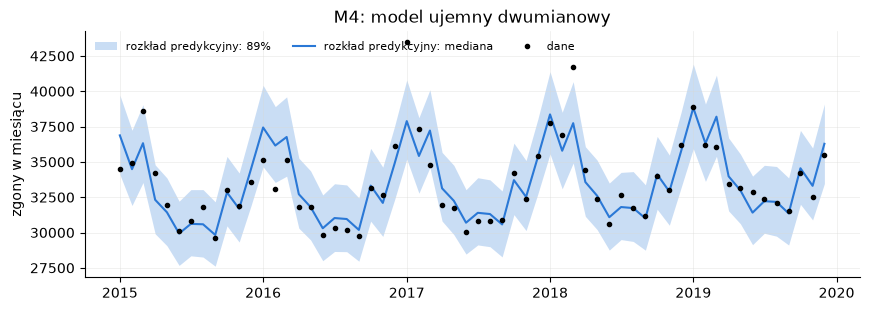

Pokrycie przedziałem predykcyjnym 89%: M4 95%


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,7.0019,0.0055,7,7,7390,2629,1.00,6.4e-05,0.00011
trend,0.01273,0.0038,0.0067,0.019,6877,3249,1.00,4.6e-05,6.9e-05
cv,0.0426,0.0045,0.036,0.05,4249,3161,1.00,6.9e-05,7.4e-05


In [27]:
with pm.Model(coords=coords) as m4:
    month, t, days, y = data_containers(pre)
    intercept = pm.Normal("intercept", np.log(1_000), 0.5)
    trend = pm.Normal("trend", 0, 0.05)
    month_effect = pm.ZeroSumNormal("month_effect", sigma=0.2, dims="month")
    mu = pm.Deterministic("mu", pm.math.exp(np.log(days) + intercept + trend * t + month_effect[month]), dims="date")
    cv = pm.HalfNormal("cv", 0.1)
    pm.NegativeBinomial("deaths", mu=mu, alpha=1 / cv**2, observed=y, dims="date")

idata4 = fit(m4)
plot_fit(idata4, pre, "M4: model ujemny dwumianowy")
print(f"Pokrycie przedziałem predykcyjnym 89%: M4 {coverage(idata4):.0%}")
az.summary(idata4, var_names=["intercept", "trend", "cv"])

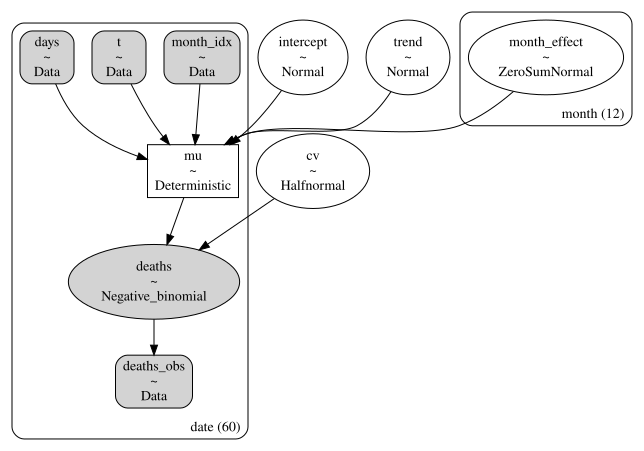

In [28]:
pm.model_to_graphviz(m4)

Efekty miesięcy w modelu M4 są w skali logarytmicznej; po przekształceniu $e^{g_m}$ otrzymujemy względny poziom dziennej liczby zgonów w danym miesiącu:

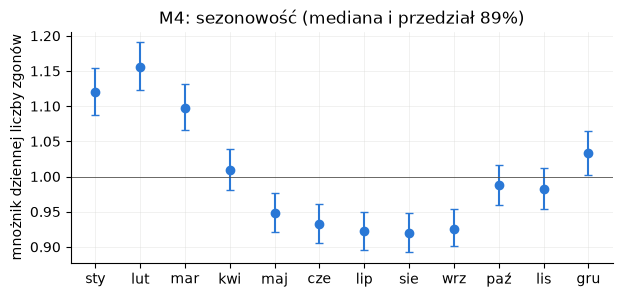

Roczna zmiana dziennej liczby zgonów: +1.28%


In [29]:
plot_month_effects(np.exp(idata4.posterior["month_effect"]), "mnożnik dziennej liczby zgonów",
                   "M4: sezonowość (mediana i przedział 89%)", ref=1)
print(f"Roczna zmiana dziennej liczby zgonów: {float(np.expm1(idata4.posterior['trend']).mean()):+.2%}")

### 3.6. Porównanie modeli: walidacja krzyżowa LOO

Do porównania modeli użyjemy przybliżonej **walidacji krzyżowej typu „pomiń jeden”** (*leave-one-out*, LOO), obliczanej z jednego dopasowania modelu metodą PSIS (*Pareto-smoothed importance sampling*). Kryterium jest oczekiwany logarytm gęstości predykcyjnej dla nowych danych, $\mathrm{elpd}_{\mathrm{loo}} = \sum_i \log p(y_i \mid y_{-i})$ — im większy, tym lepiej. W tabeli:

* `elpd` — oszacowanie $\mathrm{elpd}_{\mathrm{loo}}$, `se` — jego błąd standardowy,
* `p` — efektywna liczba parametrów,
* `elpd_diff`, `dse` — różnica względem najlepszego modelu i jej błąd standardowy (różnica mniejsza niż ok. 2 `dse` nie jest przekonująca),
* `weight` — wagi uśredniania modeli (*stacking*).

Pomijamy model M3, który jest wyraźnie błędnie wyspecyfikowany. Uwaga: porównujemy modele z ciągłym (normalnym) i dyskretnym (ujemnym dwumianowym) rozkładem obserwacji. Jest to dopuszczalne w przybliżeniu, bo dla dużych liczebności gęstość rozkładu ciągłego w punkcie $y$ jest bliska prawdopodobieństwu przedziału $[y - \tfrac12, y + \tfrac12]$.

In [30]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # ostrzeżenia o wartościach k̂ omawiamy poniżej
    comparison = az.compare({"M0": idata0, "M1": idata1, "M2": idata2, "M4": idata4})
comparison

,rank,elpd_diff,dse,p_worse,diag_diff,diag_elpd,p,elpd,se,weight
M4,0,0.0,0.0,NaN,,2 k̂ > 0.70,14.2,-530.0,9.9,0.94
M2,1,-3.0,2.7,0.88,N < 100,1 k̂ > 0.70,13.4,-530.0,11.0,0.06
M1,2,-8.0,3.1,0.99,N < 100,2 k̂ > 0.70,12.9,-540.0,10.0,0.00
M0,3,-40.0,5.5,1.00,N < 100,,2.9,-560.0,8.2,0.00


Kolumna `p_worse` to przybliżone prawdopodobieństwo, że dany model ma gorszą zdolność predykcyjną niż najlepszy. Kolumny `diag_elpd` i `diag_diff` zawierają ostrzeżenia: `k̂ > 0.70` oznacza, że dla tylu obserwacji przybliżenie PSIS jest niewiarygodne (usunięcie tej obserwacji bardzo zmienia rozkład a posteriori), a `N < 100` — że przy tak małej liczbie obserwacji przybliżenie normalne dla różnicy `elpd_diff` (a więc i `dse`, `p_worse`) jest mało dokładne. Sprawdźmy, których miesięcy dotyczą problematyczne wartości $\hat k$:

In [31]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    loo4 = az.loo(idata4, pointwise=True)
print(loo4)
k = pd.Series(loo4.pareto_k.values, index=pre.index.strftime("%Y-%m"), name="k̂")
k[k > 0.5].round(2).to_frame().T

Computed from 4000 posterior samples and 60 observations log-likelihood matrix.

         Estimate       SE
elpd_loo  -529.30     9.92
p_loo       14.18        -

There has been a warning during the calculation. Please check the results.
------

Pareto k diagnostic values:
                         Count   Pct.
(-Inf, 0.70]   (good)       58   96.7%
   (0.70, 1]   (bad)         2    3.3%
    (1, Inf)   (very bad)    0    0.0%



date,2015-01,2017-01,2017-03,2018-03
k̂,0.64,0.92,0.61,0.71


Wartości $\hat k > 0{,}7$ mają styczeń 2017 i marzec 2018 — miesiące silnych epidemii grypy (sezony 2016/2017 i 2017/2018), w których zgonów było znacznie więcej, niż przewiduje model (por. wykres w p. 2.4). Model zakłada niezależne odchylenia w kolejnych miesiącach o „lekkich” ogonach, a epidemie grypy powodują duże, skorelowane w czasie odchylenia. Nie zmienia to wniosków z porównania (różnice między modelami są duże), ale wskazuje kierunek ulepszenia modelu (por. zadanie 3).

❓ **Pytanie 4.**
(a) W modelu M1 efekt lutego jest wyraźnie mniejszy niż efekty stycznia i marca, a w modelu M4 luty ma największy efekt ze wszystkich miesięcy. Wyjaśnij tę pozorną sprzeczność.
(b) Po czym w kontroli predykcyjnej a posteriori widać, że model Poissona jest nieodpowiedni? Czy problem zniknąłby, gdybyśmy analizowali kraj 1000 razy mniejszy (np. Liechtenstein, kilkadziesiąt zgonów miesięcznie)?
(c) Model M4 jest lepszy od M2, ale różnica $\mathrm{elpd}_{\mathrm{loo}}$ jest niewielka w porównaniu z jej błędem standardowym. W jakich sytuacjach różnice między addytywnym modelem normalnym a multiplikatywnym modelem ujemnym dwumianowym mogłyby być większe?

## 4. Zgony nadmiarowe w Polsce — wnioskowanie kontrfaktyczne

### 4.1. Prognoza kontrfaktyczna

Pytanie kontrfaktyczne brzmi: *ile osób zmarłoby w latach 2020–2023, gdyby zależności z lat 2015–2019 (sezonowość, trend, zmienność losowa) obowiązywały nadal?* Aby na nie odpowiedzieć, podmieniamy w modelu dane na wartości z okresu analizy (miesiące, czas, liczba dni) i losujemy z rozkładu predykcyjnego a posteriori. Zaobserwowane liczby zgonów z lat 2020–2023 **nie są** przy tym wykorzystywane — zastępujemy je zerami, które służą tylko do ustalenia rozmiaru danych.

Założenie przyczynowe jest silne: przyjmujemy, że jedyną przyczyną odchyleń od prognozy była pandemia (i jej skutki pośrednie). Inne zdarzenia (np. upały, migracje) również trafią do „zgonów nadmiarowych”.

In [32]:
def counterfactual(model, idata, df, extra=()):
    # Rozkład predykcyjny liczby zgonów dla danych df (bez użycia zaobserwowanych zgonów).
    # `extra` — nazwy dodatkowych kontenerów pm.Data modelu (równe nazwom kolumn df), które trzeba
    # podmienić, np. zmiennych objaśniających dodanych w zadaniach
    with model:
        values = {"month_idx": df["month"].to_numpy(), "t": df["t"].to_numpy(), "days": df["days"].to_numpy(),
                  "deaths_obs": np.zeros(len(df), dtype=int)}
        values.update({name: df[name].to_numpy() for name in extra})
        pm.set_data(values, coords={"date": df.index})
        pp = pm.sample_posterior_predictive(idata, var_names=["deaths"], predictions=True,
                                            random_seed=RANDOM_SEED, progressbar=False)
    return pp.predictions["deaths"]


expected4 = counterfactual(m4, idata4, post)
expected4

Sampling: [deaths]


<xarray.DataArray 'deaths' (chain: 4, draw: 1000, date: 48)> Size: 2MB
array([[[38048, 37724, 38343, ..., 37302, 32036, 37372],
        [38477, 40305, 37134, ..., 35360, 36502, 41142],
        [38271, 36237, 38276, ..., 36631, 33664, 40251],
        ...,
        [37995, 36314, 37841, ..., 35786, 33400, 35528],
        [38799, 35021, 37373, ..., 31930, 31678, 36639],
        [38264, 36968, 37960, ..., 35685, 33600, 36240]],

       [[38962, 35544, 38923, ..., 34004, 36159, 37997],
        [40774, 39450, 41250, ..., 35220, 35162, 36740],
        [38256, 40631, 36481, ..., 38871, 35152, 40263],
        ...,
        [40889, 36696, 43404, ..., 37577, 36197, 39100],
        [37353, 37235, 40834, ..., 38377, 37090, 41008],
        [40713, 36713, 39887, ..., 38671, 37159, 41663]],

       [[42162, 37644, 37938, ..., 35745, 36185, 36976],
        [39517, 40273, 37040, ..., 37872, 34319, 36671],
        [37371, 37884, 38143, ..., 36191, 36404, 39815],
        ...,
        [40063, 37099, 40001, ..., 35250, 33014, 36750],
        [40144, 41529, 35582, ..., 34760, 37747, 40618],
        [39839, 36144, 39773, ..., 35210, 32910, 34364]],

       [[37027, 36990, 40427, ..., 37722, 35202, 37177],
        [42100, 38809, 36352, ..., 35940, 37518, 35851],
        [38326, 37550, 39616, ..., 34973, 36752, 41040],
        ...,
        [39189, 35627, 38816, ..., 35664, 34231, 37410],
        [41242, 38363, 40444, ..., 34710, 32933, 37792],
        [38602, 39267, 42626, ..., 39643, 35121, 37767]]],
      shape=(4, 1000, 48))
Coordinates:
  * chain    (chain) int64 32B 0 1 2 3
  * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
  * date     (date) datetime64[us] 384B 2020-01-01 2020-02-01 ... 2023-12-01

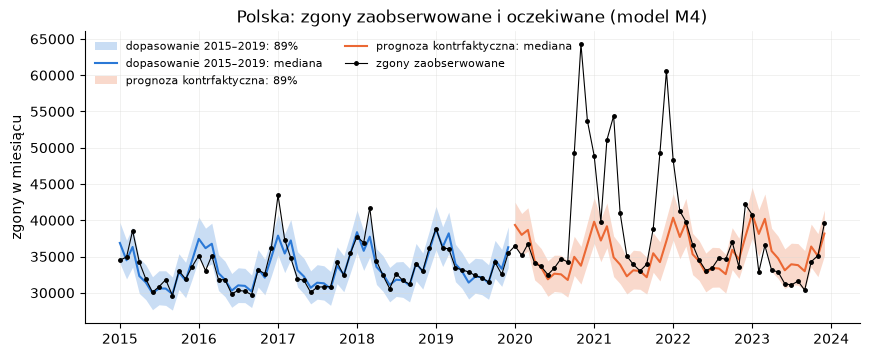

In [33]:
fig, ax = plt.subplots(figsize=(10, 3.8))
plot_band(ax, pre.index, idata4.posterior_predictive["deaths"], color="C0", label="dopasowanie 2015–2019")
plot_band(ax, post.index, expected4, color="C1", label="prognoza kontrfaktyczna")
ax.plot(pl.index[pl.index < "2024"], pl["deaths"][pl.index < "2024"], "o-", color="k", ms=2.5, lw=0.8,
        label="zgony zaobserwowane")
ax.set(ylabel="zgony w miesiącu", title="Polska: zgony zaobserwowane i oczekiwane (model M4)")
ax.legend(loc="upper left", fontsize=8, ncols=2)
plt.show()

### 4.2. Miesięczne i skumulowane zgony nadmiarowe

Zgony nadmiarowe obliczamy **dla każdej próbki** rozkładu predykcyjnego osobno, dzięki czemu otrzymujemy ich rozkład a posteriori. Biblioteka xarray automatycznie dopasowuje tablice po nazwach wymiarów (`date`), więc odejmowanie tablicy obserwacji (wymiar `date`) od tablicy prognoz (wymiary `chain`, `draw`, `date`) działa „samo”.

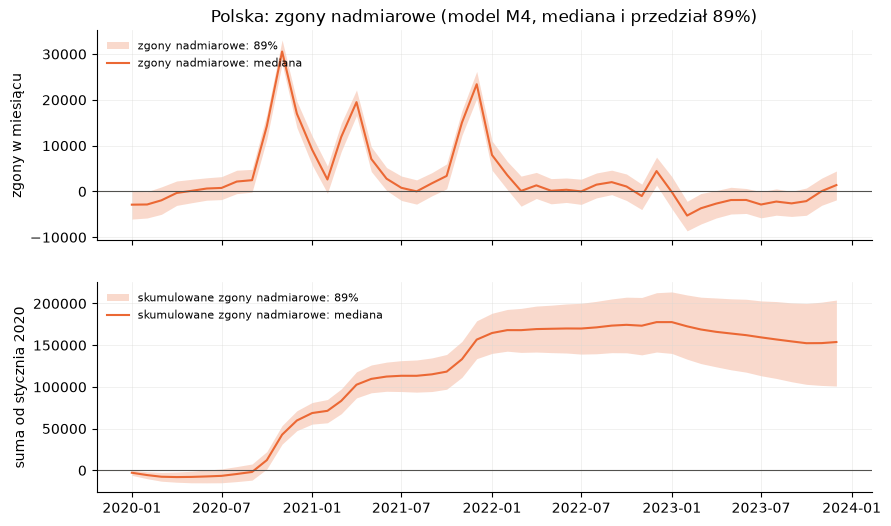

In [34]:
observed = xr.DataArray(post["deaths"].to_numpy(), dims="date", coords={"date": post.index})
excess4 = observed - expected4
cumulative4 = excess4.cumsum(dim="date")

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
plot_band(axes[0], post.index, excess4, color="C1", label="zgony nadmiarowe")
plot_band(axes[1], post.index, cumulative4, color="C1", label="skumulowane zgony nadmiarowe")
for ax in axes:
    ax.axhline(0, color="#52514e", lw=0.8)
    ax.legend(loc="upper left", fontsize=8)
axes[0].set(ylabel="zgony w miesiącu", title="Polska: zgony nadmiarowe (model M4, mediana i przedział 89%)")
axes[1].set(ylabel="suma od stycznia 2020")
plt.show()

### 4.3. Podsumowanie roczne

Zsumujmy wyniki w latach kalendarzowych i porównajmy je z liczbą zgonów **zgłoszonych** jako zgony z powodu COVID-19 (plik `country_covariates.csv`; kolumny `covid_deaths_pm_*` zawierają skumulowaną liczbę zgonów przypisanych COVID-19 na milion mieszkańców na koniec danego roku według danych WHO zebranych przez Our World in Data).

In [35]:
def fmt_interval(draws, scale=1.0, digits=0):
    # "mediana [5,5%; 94,5%]" z separatorem tysięcy i przecinkiem dziesiętnym
    lo, med, hi = np.quantile(draws, [0.055, 0.5, 0.945]) * scale
    f = lambda v: f"{v:,.{digits}f}".replace(",", " ").replace(".", ",")
    return f"{f(med)} [{f(lo)}; {f(hi)}]"


def yearly_table(expected, df, iso="POL"):
    years = expected["date"].dt.year
    obs = xr.DataArray(df["deaths"].to_numpy(), dims="date", coords={"date": df.index})
    exp_y = expected.groupby(years).sum()
    obs_y = obs.groupby(years).sum()
    covid_cum = cov.loc[iso, ["covid_deaths_pm_2020", "covid_deaths_pm_2021", "covid_deaths_pm_2022"]].to_numpy()
    covid = dict(zip([2020, 2021, 2022], np.diff(covid_cum, prepend=0) * cov.loc[iso, "population"] / 1e6))
    rows = {}
    for yr in exp_y["year"].values:
        e = exp_y.sel(year=yr).values.ravel()
        o = float(obs_y.sel(year=yr))
        rows[yr] = {"zaobserwowane": f"{o:,.0f}".replace(",", " "),
                    "oczekiwane": fmt_interval(e),
                    "nadmiarowe": fmt_interval(o - e),
                    "wskaźnik P [%]": fmt_interval(100 * (o - e) / e, digits=1),
                    "zgłoszone zgony COVID-19": f"{covid[yr]:,.0f}".replace(",", " ") if yr in covid else "—"}
    return pd.DataFrame(rows).T


yearly_table(expected4, post)

,zaobserwowane,oczekiwane,nadmiarowe,wskaźnik P [%],zgłoszone zgony COVID-19
2020,478 138,418 382 [406 718; 430 561],59 756 [47 577; 71 420],"14,3 [11,1; 17,6]",28 250
2021,519 877,422 923 [409 230; 436 934],96 954 [82 943; 110 647],"22,9 [19,0; 27,0]",69 696
2022,449 350,428 036 [412 699; 444 201],21 314 [5 149; 36 651],"5,0 [1,2; 8,9]",25 071
2023,409 471,433 624 [415 866; 453 014],-24 154 [-43 543; -6 395],"-5,6 [-9,6; -1,5]",—


### 4.4. Wrażliwość wyniku na wybór modelu

Liczba zgonów nadmiarowych nie jest „obserwowana”, lecz zależy od modelu kontrfaktycznego. Porównajmy łączną liczbę zgonów nadmiarowych w latach 2020–2022 według modeli M1 (bez trendu), M2 (trend, rozkład normalny) i M4.

Sampling: [deaths]
Sampling: [deaths]


M1: zgony nadmiarowe 2020–2022 = 241 844 [221 880; 262 553]
M2: zgony nadmiarowe 2020–2022 = 183 082 [147 300; 219 167]
M4: zgony nadmiarowe 2020–2022 = 177 656 [141 815; 212 895]


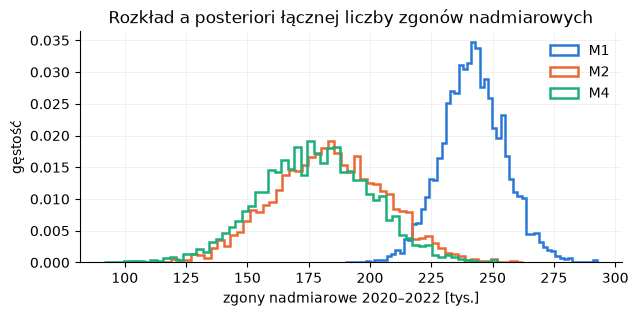

In [36]:
totals = {}
for name, model, idata_m in [("M1", m1, idata1), ("M2", m2, idata2), ("M4", m4, idata4)]:
    expected = expected4 if name == "M4" else counterfactual(model, idata_m, post)
    excess = (observed - expected).sel(date=slice("2020-01-01", "2022-12-31")).sum("date")
    totals[name] = excess.values.ravel()
    print(f"{name}: zgony nadmiarowe 2020–2022 = {fmt_interval(totals[name])}")

fig, ax = plt.subplots(figsize=(7, 3))
for i, (name, v) in enumerate(totals.items()):
    ax.hist(v / 1000, bins=60, density=True, histtype="step", lw=1.8, color=f"C{i}", label=name)
ax.set(xlabel="zgony nadmiarowe 2020–2022 [tys.]", ylabel="gęstość", title="Rozkład a posteriori łącznej liczby zgonów nadmiarowych")
ax.legend()
plt.show()

❓ **Pytanie 5.**
(a) Dlaczego niepewność prognozy kontrfaktycznej rośnie z upływem czasu?
(b) Według modelu M4 w 2023 r. zgonów było **mniej**, niż należałoby oczekiwać. Podaj co najmniej dwa możliwe wyjaśnienia (wskazówka: tabela w p. 2.2). Czy przedłużanie trendu liniowego z lat 2015–2019 na 8 lat naprzód jest rozsądne?
(c) Dlaczego model bez trendu (M1) daje znacznie więcej zgonów nadmiarowych? Który wynik uważasz za najbardziej wiarygodny i dlaczego?
(d) Porównaj liczbę zgonów nadmiarowych z liczbą zgłoszonych zgonów z powodu COVID-19. Jakie mogą być przyczyny różnicy?

## 5. Wiele krajów: model hierarchiczny dla Europy

### 5.1. Dane

Rozszerzamy analizę na wszystkie kraje europejskie z kompletnymi danymi miesięcznymi za lata 2015–2022 (przynależność do kontynentu bierzemy z pliku `country_covariates.csv`). Okres analizy skracamy do lat 2020–2022, dla których mamy dane we wszystkich tych krajach.

In [37]:
period = monthly[(monthly["date"] >= "2015-01-01") & (monthly["date"] < "2023-01-01")]
n_months = period.groupby("iso3c").size()
europe = [c for c in n_months.index if n_months[c] == 96 and cov["continent"].get(c) == "Europe"]
names = cov.loc[europe, "location"]
print(len(europe), "krajów:", ", ".join(names))

eu = add_features(period[period["iso3c"].isin(europe)])
eu["c"] = eu["iso3c"].map({iso: i for i, iso in enumerate(europe)})   # indeks kraju

44 krajów: Albania, Austria, Belgium, Bulgaria, Bosnia and Herzegovina, Belarus, Switzerland, Cyprus, Czechia, Germany, Denmark, Spain, Estonia, Finland, France, Faroe Islands, United Kingdom, Gibraltar, Greece, Croatia, Hungary, Ireland, Iceland, Italy, Kosovo, Liechtenstein, Lithuania, Luxembourg, Latvia, Monaco, Moldova, North Macedonia, Malta, Netherlands, Norway, Poland, Portugal, Romania, Russia, San Marino, Serbia, Slovakia, Slovenia, Sweden


Kraje różnią się liczbą zgonów o kilka rzędów wielkości: od ok. 1 zgonu dziennie w Liechtensteinie i San Marino do ok. 5000 w Rosji. Aby te same rozkłady a priori pasowały do wszystkich krajów, do ekspozycji dodajemy **skalę** kraju $s_c$ — średnią dzienną liczbę zgonów w latach 2015–2019. Parametry modelu opisują wtedy **względne** odchylenia od tej skali.

In [38]:
eu_pre = eu[eu["date"] < "2020-01-01"]
scale = eu_pre.groupby("iso3c")["deaths"].sum() / eu_pre.groupby("iso3c")["days"].sum()
eu["log_offset"] = np.log(eu["days"]) + np.log(eu["iso3c"].map(scale))

eu_pre = eu[eu["date"] < "2020-01-01"].reset_index(drop=True)
eu_post = eu[eu["date"] >= "2020-01-01"].reset_index(drop=True)
scale.sort_values().round(1).to_frame("średnio zgonów dziennie (2015–2019)").T

iso3c,SMR,LIE,GIB,FRO,MCO,ISL,MLT,LUX,CYP,KOS,...,HUN,NLD,ROU,POL,ESP,FRA,GBR,ITA,DEU,RUS
średnio zgonów dziennie (2015–2019),0.7,0.7,0.8,1.1,1.4,6.2,9.7,11.4,16.1,24.0,...,356.5,411.7,716.3,1100.4,1145.6,1617.6,1658.1,1767.7,2553.6,5067.3


### 5.2. Łączenie informacji między krajami

Dla każdego kraju $c$ stosujemy model analogiczny do M4:

$$
\text{zgony}_{c,t} \sim \mathrm{NB}\!\left(\lambda_{c,t},\ 1/c_c^2\right), \qquad
\log \lambda_{c,t} = \log(\text{dni}_t) + \log s_c + a_c + b_c\, t + g_{c,m(t)}.
$$

Możliwe są trzy strategie:

* **brak łączenia** (*no pooling*) — każdy kraj ma własne, niezależne parametry; dla małych krajów z bardzo zaszumionymi danymi oszacowania (np. trendu) są niestabilne,
* **pełne łączenie** (*complete pooling*) — wszystkie kraje mają te same parametry; ignoruje to rzeczywiste różnice między krajami,
* **częściowe łączenie** (*partial pooling*) — **model hierarchiczny**: parametry krajów są różne, ale pochodzą ze wspólnego rozkładu, którego parametry (**hiperparametry**) również szacujemy z danych.

W modelu hierarchicznym przyjmujemy:

$$
b_c \sim \mathcal{N}(\mu_b, \sigma_b^2), \qquad
g_{c,\cdot} = g_{\cdot} + \sigma_g\, \delta_{c,\cdot}, \qquad
\log c_c \sim \mathcal{N}(\mu_{c}, \sigma_{c}^2),
$$

gdzie $g$ to wspólny profil sezonowy (o sumie zero), a $\delta_c$ — odchylenia profilu kraju $c$ (również o sumie zero). Jeżeli dane wskażą, że kraje mają podobne trendy, oszacowanie $\sigma_b$ będzie małe, a trendy małych krajów zostaną „ściągnięte” (*shrinkage*) w stronę średniej $\mu_b$. Kraje „pożyczają siłę” od siebie nawzajem.

**Parametryzacja niescentrowana.** Zamiast $b_c \sim \mathcal{N}(\mu_b, \sigma_b^2)$ piszemy $b_c = \mu_b + \sigma_b z_c$, $z_c \sim \mathcal{N}(0, 1)$. Obie postacie definiują ten sam model, ale druga ma znacznie prostszą geometrię rozkładu a posteriori (unika tzw. „lejka Neala”, w którym przy małych $\sigma_b$ parametry $b_c$ muszą być bardzo blisko siebie). W modelach hierarchicznych jest to często warunek próbkowania bez rozbieżności.

Funkcja poniżej buduje model w wersji hierarchicznej (`pooled=True`) lub bez łączenia (`pooled=False`).

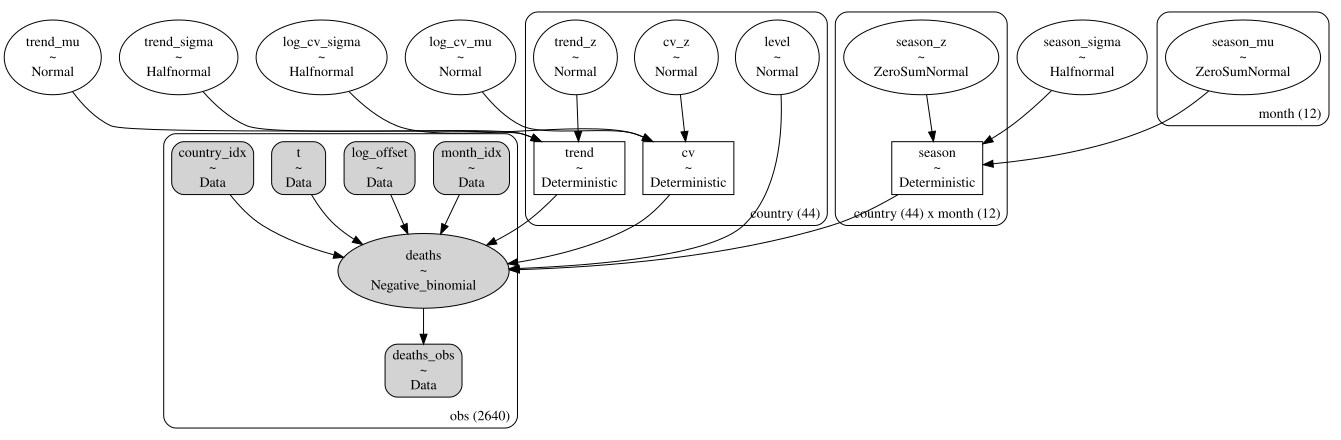

In [39]:
def europe_model(df, pooled=True):
    coords = {"country": europe, "month": MONTHS, "obs": np.arange(len(df))}
    with pm.Model(coords=coords) as model:
        c = pm.Data("country_idx", df["c"].to_numpy(), dims="obs")
        month = pm.Data("month_idx", df["month"].to_numpy(), dims="obs")
        t = pm.Data("t", df["t"].to_numpy(), dims="obs")
        offset = pm.Data("log_offset", df["log_offset"].to_numpy(), dims="obs")
        y = pm.Data("deaths_obs", df["deaths"].to_numpy(), dims="obs")

        level = pm.Normal("level", 0, 0.2, dims="country")
        if pooled:
            trend_mu = pm.Normal("trend_mu", 0, 0.03)
            trend_sigma = pm.HalfNormal("trend_sigma", 0.02)
            trend_z = pm.Normal("trend_z", 0, 1, dims="country")
            trend = pm.Deterministic("trend", trend_mu + trend_sigma * trend_z, dims="country")

            season_mu = pm.ZeroSumNormal("season_mu", sigma=0.2, dims="month")
            season_sigma = pm.HalfNormal("season_sigma", 0.1)
            season_z = pm.ZeroSumNormal("season_z", sigma=1, dims=("country", "month"), n_zerosum_axes=1)
            season = pm.Deterministic("season", season_mu + season_sigma * season_z, dims=("country", "month"))

            log_cv_mu = pm.Normal("log_cv_mu", np.log(0.03), 0.5)
            log_cv_sigma = pm.HalfNormal("log_cv_sigma", 0.5)
            cv_z = pm.Normal("cv_z", 0, 1, dims="country")
            cv = pm.Deterministic("cv", pm.math.exp(log_cv_mu + log_cv_sigma * cv_z), dims="country")
        else:
            trend = pm.Normal("trend", 0, 0.03, dims="country")
            season = pm.ZeroSumNormal("season", sigma=0.2, dims=("country", "month"), n_zerosum_axes=1)
            cv = pm.HalfNormal("cv", 0.1, dims="country")

        mu = pm.math.exp(offset + level[c] + trend[c] * t + season[c, month])
        pm.NegativeBinomial("deaths", mu=mu, alpha=1 / cv[c] ** 2, observed=y, dims="obs")
    return model


eu_model = europe_model(eu_pre, pooled=True)
pm.model_to_graphviz(eu_model)

In [40]:
with eu_model:
    idata_eu = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

eu_model_np = europe_model(eu_pre, pooled=False)
with eu_model_np:
    idata_np = pm.sample(random_seed=RANDOM_SEED, progressbar=False)

check(idata_eu)
check(idata_np)

az.summary(idata_eu, var_names=["trend_mu", "trend_sigma", "season_sigma", "log_cv_mu", "log_cv_sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [level, trend_mu, trend_sigma, trend_z, season_mu, season_sigma, season_z, log_cv_mu, log_cv_sigma, cv_z]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 18 seconds.
Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [level, trend, season, cv]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 13 seconds.


rozbieżności: 0, maks. R-hat: 1.006, min. ESS (bulk): 1055
rozbieżności: 0, maks. R-hat: 1.007, min. ESS (bulk): 1962


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
trend_mu,0.0034,0.00171,0.00074,0.0062,1054,1292,1.00,5.3e-05,3.9e-05
trend_sigma,0.00957,0.00139,0.0076,0.012,1629,1900,1.00,3.5e-05,2.5e-05
season_sigma,0.02133,0.00166,0.019,0.024,1259,2249,1.00,4.7e-05,2.4e-05
log_cv_mu,-3.126,0.041,-3.2,-3.1,1355,1884,1.00,0.0011,0.0007
log_cv_sigma,0.216,0.036,0.16,0.28,1711,2105,1.00,0.00086,0.0006


### 5.3. Efekt częściowego łączenia

Porównajmy oszacowania trendu $b_c$ w obu modelach. Na osi poziomej — wielkość kraju (średnia dzienna liczba zgonów, skala logarytmiczna).

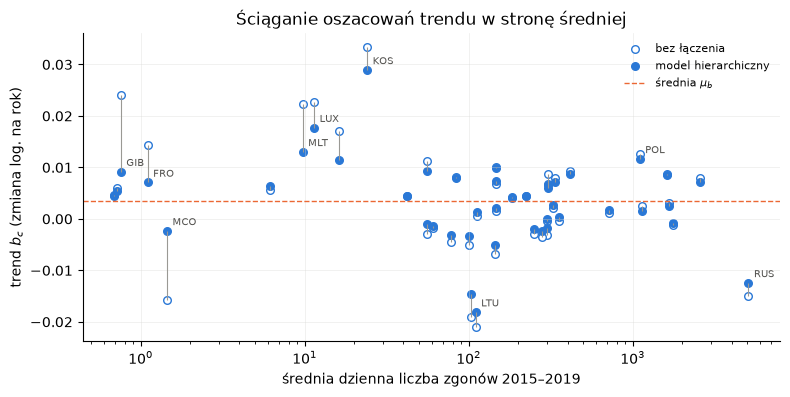

In [41]:
trend_np = idata_np.posterior["trend"].median(("chain", "draw")).to_series()
trend_hier = idata_eu.posterior["trend"].median(("chain", "draw")).to_series()
size_c = scale[europe]

fig, ax = plt.subplots(figsize=(9, 4))
ax.vlines(size_c, trend_np, trend_hier, color="#9a9994", lw=0.8)
ax.scatter(size_c, trend_np, s=30, facecolors="white", edgecolors="C0", label="bez łączenia")
ax.scatter(size_c, trend_hier, s=30, color="C0", label="model hierarchiczny")
ax.axhline(float(idata_eu.posterior["trend_mu"].mean()), color="C1", ls="--", lw=1, label="średnia $\\mu_b$")
for iso in ["GIB", "FRO", "MCO", "MLT", "LUX", "KOS", "POL", "RUS", "LTU"]:
    ax.annotate(iso, (size_c[iso], trend_hier[iso]), xytext=(4, 4), textcoords="offset points", fontsize=7, color="#52514e")
ax.set_xscale("log")
ax.set(xlabel="średnia dzienna liczba zgonów 2015–2019", ylabel="trend $b_c$ (zmiana log. na rok)",
       title="Ściąganie oszacowań trendu w stronę średniej")
ax.legend(fontsize=8)
plt.show()

### 5.4. Wskaźniki P dla krajów Europy

Wykonujemy prognozę kontrfaktyczną dla lat 2020–2022 dla wszystkich krajów naraz i dla każdego kraju obliczamy wskaźnik P za cały okres 2020–2022, osobno za lata 2021–2022 (okres, w którym dostępne były szczepionki) oraz za 2020 r. (przed szczepieniami; przyda się w zadaniu 6).

In [42]:
with eu_model:
    pm.set_data({"country_idx": eu_post["c"].to_numpy(), "month_idx": eu_post["month"].to_numpy(),
                 "t": eu_post["t"].to_numpy(), "log_offset": eu_post["log_offset"].to_numpy(),
                 "deaths_obs": np.zeros(len(eu_post), dtype=int)},
                coords={"obs": np.arange(len(eu_post))})
    eu_cf = pm.sample_posterior_predictive(idata_eu, var_names=["deaths"], predictions=True,
                                           random_seed=RANDOM_SEED, progressbar=False)

expected_eu = eu_cf.predictions["deaths"].assign_coords(
    country=("obs", eu_post["iso3c"].to_numpy()), year=("obs", eu_post["year"].to_numpy()))
observed_eu = xr.DataArray(eu_post["deaths"].to_numpy(), dims="obs", coords=expected_eu["obs"].coords)


def p_score(years):
    sel = expected_eu["year"].isin(years)
    e = expected_eu.where(sel, 0).groupby("country").sum()
    o = observed_eu.where(sel, 0).groupby("country").sum()
    return 100 * (o - e) / e, o - e


p_all, excess_all = p_score([2020, 2021, 2022])
p_late, _ = p_score([2021, 2022])
p_2020, _ = p_score([2020])

pscores = pd.DataFrame({
    "P_2020_2022": p_all.median(("chain", "draw")).to_series(),
    "P_lo": p_all.quantile(0.055, ("chain", "draw")).to_series(),
    "P_hi": p_all.quantile(0.945, ("chain", "draw")).to_series(),
    "P_2021_2022": p_late.mean(("chain", "draw")).to_series(),
    "P_2021_2022_sd": p_late.std(("chain", "draw")).to_series(),
    "P_2020": p_2020.mean(("chain", "draw")).to_series(),
    "P_2020_sd": p_2020.std(("chain", "draw")).to_series(),
    "excess": excess_all.median(("chain", "draw")).to_series(),
})
pscores.index.name = "iso3c"
pscores["country"] = names
pscores["excess_per_100k"] = pscores["excess"] / cov.loc[pscores.index, "population"] * 1e5
pscores.sort_values("P_2020_2022", ascending=False).round(1).head(10)

Sampling: [deaths]


,P_2020_2022,P_lo,P_hi,P_2021_2022,P_2021_2022_sd,P_2020,P_2020_sd,excess,country,excess_per_100k
iso3c,,,,,,,,,,
MKD,26.3,21.8,31.2,26.2,3.3,26.9,3.1,15973.5,North Macedonia,763.0
ALB,25.6,20.7,30.8,25.4,3.6,26.2,3.4,16757.5,Albania,589.6
BLR,24.7,21.6,28.0,26.8,2.4,20.7,2.0,90095.0,Belarus,944.9
RUS,22.5,19.7,25.3,24.0,2.0,19.6,1.7,1190995.5,Russia,823.0
BGR,20.9,17.5,24.5,24.2,2.5,14.4,2.2,67821.0,Bulgaria,1000.0
BIH,19.8,15.9,23.8,21.3,2.9,16.8,2.6,21626.5,Bosnia and Herzegovina,668.8
SRB,19.5,15.6,23.6,22.0,2.9,14.8,2.5,59367.0,Serbia,864.0
LTU,19.2,16.1,22.5,21.9,2.3,14.0,1.9,21570.0,Lithuania,784.3
SMR,19.1,8.5,31.0,12.2,7.5,34.4,10.2,147.0,San Marino,436.3


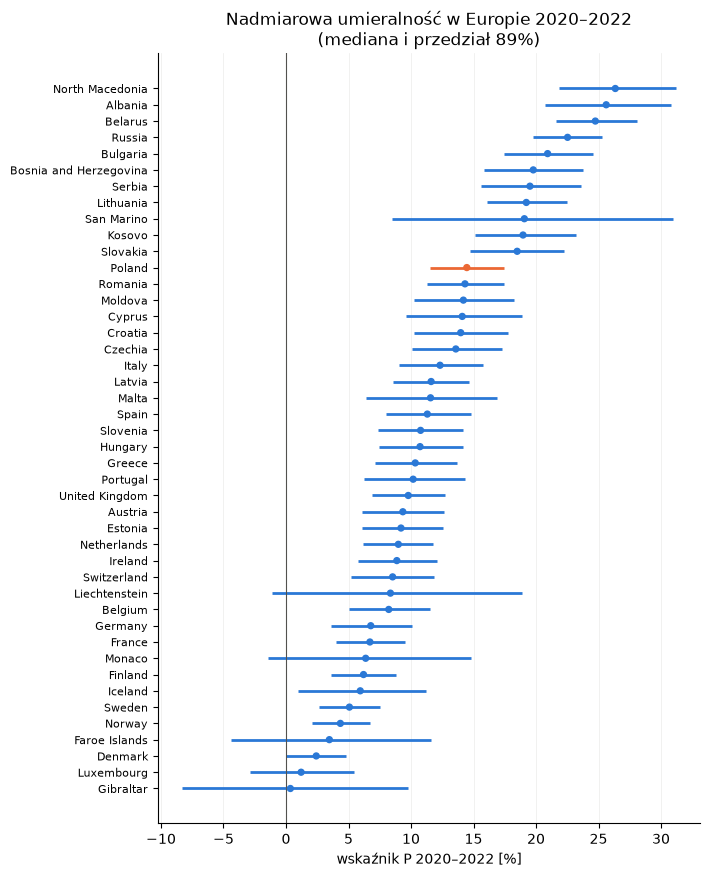

In [43]:
s = pscores.sort_values("P_2020_2022")
fig, ax = plt.subplots(figsize=(7, 10))
colors = ["C1" if iso == "POL" else "C0" for iso in s.index]
ax.hlines(np.arange(len(s)), s["P_lo"], s["P_hi"], color=colors, lw=2)
ax.scatter(s["P_2020_2022"], np.arange(len(s)), color=colors, s=18, zorder=3)
ax.set_yticks(np.arange(len(s)), s["country"], fontsize=8)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set(xlabel="wskaźnik P 2020–2022 [%]", title="Nadmiarowa umieralność w Europie 2020–2022\n(mediana i przedział 89%)")
ax.grid(axis="y", visible=False)
plt.show()

Porównajmy nasze wyniki z niezależnymi oszacowaniami publikowanymi przez Our World in Data (kolumna `owid_excess_pscore_2022`; skumulowany wskaźnik P od początku 2020 r. do końca 2022 r. obliczony metodą Karlinsky'ego i Kobaka — regresją z trendem liniowym i efektami sezonowymi dopasowaną do lat 2015–2019):

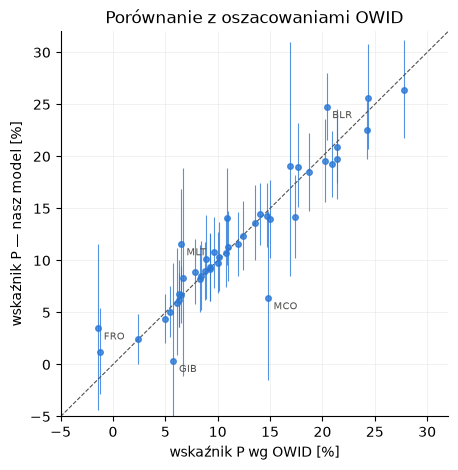

In [44]:
cmp = pscores.join(cov["owid_excess_pscore_2022"])
fig, ax = plt.subplots(figsize=(5, 5))
ax.errorbar(cmp["owid_excess_pscore_2022"], cmp["P_2020_2022"],
            yerr=[cmp["P_2020_2022"] - cmp["P_lo"], cmp["P_hi"] - cmp["P_2020_2022"]],
            fmt="o", ms=4, color="C0", elinewidth=0.8, alpha=0.8)
lim = [-5, 32]
ax.plot(lim, lim, color="#52514e", lw=0.8, ls="--")
for iso, r in cmp.iterrows():
    if abs(r["P_2020_2022"] - r["owid_excess_pscore_2022"]) > 4:
        ax.annotate(iso, (r["owid_excess_pscore_2022"], r["P_2020_2022"]), xytext=(4, -8),
                    textcoords="offset points", fontsize=7, color="#52514e")
ax.set(xlim=lim, ylim=lim, xlabel="wskaźnik P wg OWID [%]", ylabel="wskaźnik P — nasz model [%]",
       title="Porównanie z oszacowaniami OWID")
plt.show()

### 5.5. Zgony nadmiarowe a zgłoszone zgony z powodu COVID-19

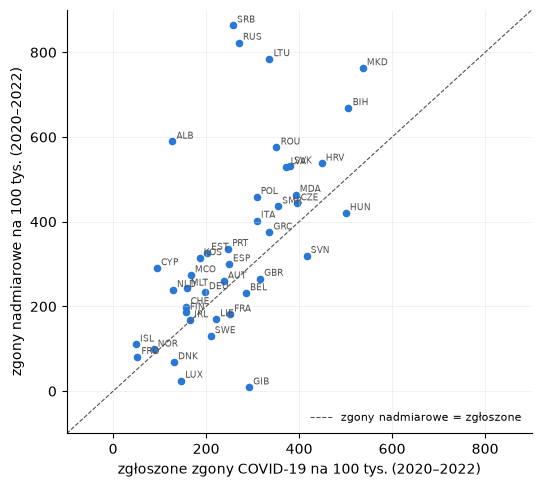

Polska: zgony nadmiarowe / zgłoszone zgony COVID-19 = 1.49


In [45]:
reported = cov.loc[pscores.index, "covid_deaths_pm_2022"] / 10        # na 100 tys. mieszkańców
fig, ax = plt.subplots(figsize=(6, 5.5))
ax.scatter(reported, pscores["excess_per_100k"], s=20, color="C0")
for iso in pscores.index:
    ax.annotate(iso, (reported[iso], pscores.loc[iso, "excess_per_100k"]), xytext=(3, 2),
                textcoords="offset points", fontsize=6.5, color="#52514e")
lim = [-100, 900]
ax.plot(lim, lim, color="#52514e", lw=0.8, ls="--", label="zgony nadmiarowe = zgłoszone")
ax.set(xlim=lim, ylim=lim, xlabel="zgłoszone zgony COVID-19 na 100 tys. (2020–2022)",
       ylabel="zgony nadmiarowe na 100 tys. (2020–2022)")
ax.legend(fontsize=8, loc="lower right")
plt.show()
print(f"Polska: zgony nadmiarowe / zgłoszone zgony COVID-19 = {pscores.loc['POL', 'excess_per_100k'] / reported['POL']:.2f}")

❓ **Pytanie 6.**
(a) Które kraje mają największe, a które najmniejsze wskaźniki P? Czy widzisz prawidłowość geograficzną?
(b) Dla których krajów przedziały wiarygodności są najszersze i dlaczego? Jak model hierarchiczny zmienił oszacowania trendu dla Gibraltaru i Monako w porównaniu z modelem bez łączenia?
(c) Dlaczego nasze wyniki są tak zbliżone do wyników OWID? Czym różni się podejście bayesowskie od podejścia z dopasowaniem regresji metodą najmniejszych kwadratów?
(d) W których krajach liczba zgonów nadmiarowych jest kilkukrotnie większa od liczby zgłoszonych zgonów COVID-19? Co może to oznaczać? Czy punkt leżący poniżej przekątnej musi oznaczać, że zgony z powodu COVID-19 były zawyżane?

## 6. Czynniki związane z nadmiarową umieralnością

### 6.1. Graf przyczynowy

Zanim zaczniemy szukać zależności w danych, warto narysować założenia o przyczynach w postaci **grafu przyczynowego** (DAG). Poniższy graf jest uproszczoną hipotezą; linią przerywaną zaznaczono zmienną nieobserwowaną.

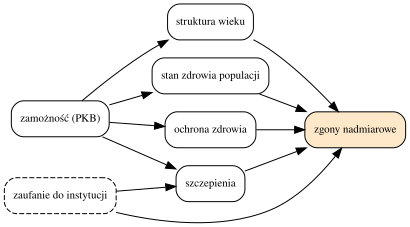

In [46]:
import graphviz

dag = graphviz.Digraph(graph_attr={"rankdir": "LR"}, node_attr={"shape": "box", "style": "rounded", "fontsize": "11"})
dag.node("PKB", "zamożność (PKB)")
dag.node("Wiek", "struktura wieku")
dag.node("Szcz", "szczepienia")
dag.node("Zdr", "stan zdrowia populacji")
dag.node("OZ", "ochrona zdrowia")
dag.node("Zauf", "zaufanie do instytucji", style="rounded,dashed")
dag.node("Y", "zgony nadmiarowe", style="rounded,filled", fillcolor="#fde9c9")
dag.edges([("PKB", "Szcz"), ("PKB", "Zdr"), ("PKB", "OZ"), ("PKB", "Wiek"),
           ("Zauf", "Szcz"), ("Zauf", "Y"),
           ("Szcz", "Y"), ("Wiek", "Y"), ("Zdr", "Y"), ("OZ", "Y")])
dag

Interesuje nas np. wpływ szczepień na zgony nadmiarowe. Oprócz ścieżki przyczynowej `szczepienia → zgony` w grafie są **ścieżki tylnymi drzwiami** (*backdoor paths*), np. `szczepienia ← PKB → ochrona zdrowia → zgony`. Przenoszą one zależność, która nie jest skutkiem szczepień: bogatsze kraje częściej szczepią **i** mają lepszą opiekę zdrowotną. Zgodnie z **kryterium tylnych drzwi** (por. d-separacja z zajęć o sieciach bayesowskich) należy zablokować te ścieżki, warunkując na PKB. Ścieżki przez nieobserwowane zaufanie do instytucji zablokować się nie da — pozostaje **zakłócenie resztowe**.

### 6.2. Dane

Jako zmienną objaśnianą przyjmujemy wskaźnik P za lata 2021–2022 obliczony w p. 5.4, a jako zmienne objaśniające — kolumny pliku `country_covariates.csv` (źródła poszczególnych zmiennych podano w Dodatku A):

| Zmienna | Znaczenie |
|---|---|
| `vaccinated_2021` | odsetek osób zaszczepionych co najmniej jedną dawką do 31.12.2021 |
| `aged_65_older` | odsetek osób w wieku 65+ |
| `gdp_per_capita` | PKB na mieszkańca wg parytetu siły nabywczej (w stałych dolarach międzynarodowych z 2011 r.) |
| `hospital_beds_per_thousand` | liczba łóżek szpitalnych na 1000 mieszkańców (najnowsze dane od 2010 r.) |
| `cardiovasc_death_rate` | zgony z powodu chorób układu krążenia na 100 tys. mieszkańców w 2017 r. |
| `stringency_2020_2021` | średni indeks restrykcyjności ograniczeń epidemicznych (0–100) w okresie 03.2020–12.2021 |

In [47]:
factors = ["vaccinated_2021", "aged_65_older", "gdp_per_capita", "hospital_beds_per_thousand",
           "cardiovasc_death_rate", "stringency_2020_2021"]
fac = pscores[["country", "P_2021_2022", "P_2021_2022_sd", "P_2020", "P_2020_sd"]].join(cov[factors])
fac["log_gdp"] = np.log(fac["gdp_per_capita"])
print("Liczba brakujących wartości:", fac[factors].isna().sum().to_dict())

# Kraje z kompletem podstawowych zmiennych (bez m.in. Gibraltaru, gdzie OWID podaje 126% zaszczepionych —
# szczepiono tam także osoby dojeżdżające do pracy z Hiszpanii)
fac_cc = fac.dropna(subset=["vaccinated_2021", "log_gdp", "aged_65_older"])
print(len(fac_cc), "krajów z kompletem danych")
fac_cc.drop(columns="country").corr().loc[["P_2021_2022"]].round(2)

Liczba brakujących wartości: {'vaccinated_2021': 0, 'aged_65_older': 6, 'gdp_per_capita': 4, 'hospital_beds_per_thousand': 3, 'cardiovasc_death_rate': 6, 'stringency_2020_2021': 2}
38 krajów z kompletem danych


,P_2021_2022,P_2021_2022_sd,P_2020,P_2020_sd,vaccinated_2021,aged_65_older,gdp_per_capita,hospital_beds_per_thousand,cardiovasc_death_rate,stringency_2020_2021,log_gdp
P_2021_2022,1.0,0.38,0.59,0.24,-0.71,-0.38,-0.76,0.42,0.84,-0.24,-0.74


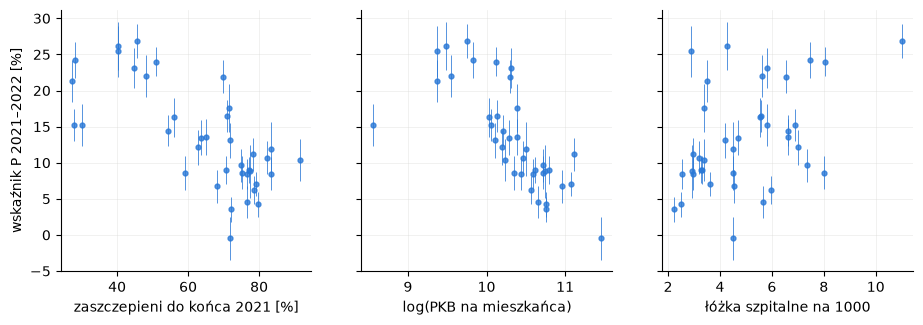

In [48]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4), sharey=True)
for ax, col, label in zip(axes, ["vaccinated_2021", "log_gdp", "hospital_beds_per_thousand"],
                          ["zaszczepieni do końca 2021 [%]", "log(PKB na mieszkańca)", "łóżka szpitalne na 1000"]):
    ax.errorbar(fac_cc[col], fac_cc["P_2021_2022"], yerr=fac_cc["P_2021_2022_sd"], fmt="o", ms=3.5, color="C0",
                elinewidth=0.7, alpha=0.8)
    ax.set(xlabel=label)
axes[0].set_ylabel("wskaźnik P 2021–2022 [%]")
plt.show()

### 6.3. Model regresji z błędem pomiaru

Wskaźniki P nie są znane dokładnie — mamy ich rozkłady a posteriori z modelu hierarchicznego, przybliżone średnią $\hat P_c$ i odchyleniem standardowym $s_c$. Zamiast traktować $\hat P_c$ jako dokładne obserwacje, użyjemy **modelu z błędem pomiaru**: prawdziwy wskaźnik $P_c$ jest zmienną ukrytą, a $\hat P_c$ — jej zaszumionym pomiarem:

$$
\hat P_c \sim \mathcal{N}(P_c, s_c^2), \qquad
P_c \sim \mathcal{N}\!\Big(\beta_0 + \sum_k \beta_k z_{k,c},\ \sigma^2\Big),
$$

gdzie $z_{k,c}$ to **wystandaryzowane** zmienne objaśniające (średnia 0, odchylenie 1). Współczynnik $\beta_k$ mówi więc, o ile punktów procentowych zmienia się oczekiwany wskaźnik P przy wzroście zmiennej $k$ o jedno odchylenie standardowe (między krajami). Kraje o niepewnych wskaźnikach (małe kraje) automatycznie mają mniejszy wpływ na wynik.

Zmienne ukryte $P_c$ można też wycałkować analitycznie — suma niezależnych zmiennych normalnych ma rozkład normalny:

$$
\hat P_c \sim \mathcal{N}\!\Big(\beta_0 + \sum_k \beta_k z_{k,c},\ \sigma^2 + s_c^2\Big).
$$

Jest to ten sam model zapisany w postaci **brzegowej** (daje ten sam rozkład a posteriori współczynników); przyda się w zadaniu 7. Funkcja `factor_model` pozwala też wybrać zmienną objaśnianą (argument `y`; odchylenie standardowe musi być w kolumnie `y + "_sd"`).

In [49]:
def factor_model(predictors, data=fac_cc, y="P_2021_2022"):
    d = data.dropna(subset=predictors)
    z = (d[predictors] - d[predictors].mean()) / d[predictors].std()
    with pm.Model(coords={"country": d.index, "factor": predictors}) as model:
        intercept = pm.Normal("intercept", 10, 10)
        beta = pm.Normal("beta", 0, 5, dims="factor")
        sigma = pm.HalfNormal("sigma", 5)
        p_true = pm.Normal("P_true", intercept + pm.math.dot(z.to_numpy(), beta), sigma, dims="country")
        pm.Normal("P_obs", p_true, d[f"{y}_sd"].to_numpy(), observed=d[y].to_numpy(), dims="country")
        idata = pm.sample(random_seed=RANDOM_SEED, target_accept=0.9, progressbar=False)
    print(f"{len(d)} krajów")
    check(idata)
    return model, idata


f1, idata_f1 = factor_model(["vaccinated_2021"])
f2, idata_f2 = factor_model(["vaccinated_2021", "log_gdp", "aged_65_older"])
az.summary(idata_f2, var_names=["intercept", "beta", "sigma"])

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta, sigma, P_true]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.
Initializing NUTS using jitter+adapt_diag...


38 krajów
rozbieżności: 0, maks. R-hat: 1.003, min. ESS (bulk): 2805


Multiprocess sampling (4 chains in 4 jobs)
NUTS: [intercept, beta, sigma, P_true]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 1 seconds.


38 krajów
rozbieżności: 0, maks. R-hat: 1.006, min. ESS (bulk): 3027


,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
intercept,13.29,0.77,12,15,5838,3602,1.00,0.01,0.013
beta[vaccinated_2021],-2.26,1.23,-4.3,-0.32,4449,3455,1.00,0.018,0.019
beta[log_gdp],-3.28,1.16,-5.1,-1.4,4634,2703,1.00,0.017,0.018
beta[aged_65_older],-0.68,0.86,-2.1,0.68,5513,3576,1.00,0.012,0.014
sigma,3.95,0.69,2.9,5.1,3026,2887,1.00,0.012,0.01


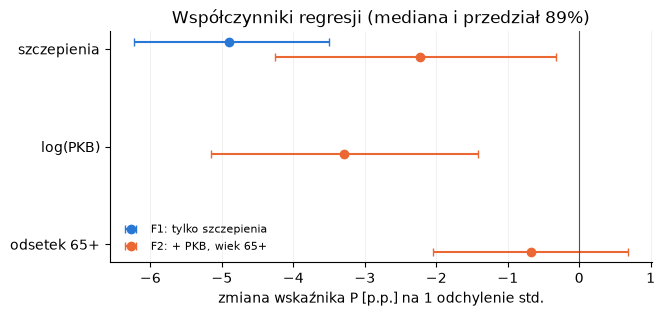

In [50]:
fig, ax = plt.subplots(figsize=(7, 3))
for i, (label, d) in enumerate([("F1: tylko szczepienia", idata_f1), ("F2: + PKB, wiek 65+", idata_f2)]):
    beta = d.posterior["beta"]
    lo, med, hi = beta.quantile([0.055, 0.5, 0.945], dim=("chain", "draw")).values
    pos = np.array([["vaccinated_2021", "log_gdp", "aged_65_older"].index(f) for f in beta["factor"].values])
    ax.errorbar(med, pos + 0.15 * i, xerr=[med - lo, hi - med], fmt="o", color=f"C{i}", capsize=3, label=label)
ax.axvline(0, color="#52514e", lw=0.8)
ax.set_yticks([0.07, 1.07, 2.07], ["szczepienia", "log(PKB)", "odsetek 65+"])
ax.invert_yaxis()
ax.set(xlabel="zmiana wskaźnika P [p.p.] na 1 odchylenie std.", title="Współczynniki regresji (mediana i przedział 89%)")
ax.legend(fontsize=8, loc="lower left")
ax.grid(axis="y", visible=False)
plt.show()

W modelu F1 szczepienia mają silny związek ze wskaźnikiem P. Po uwzględnieniu PKB (model F2) współczynnik szczepień wyraźnie maleje — część zależności widocznej w F1 wynikała z zamożności krajów, zgodnie z przewidywaniami grafu przyczynowego. Może też zaskakiwać, że współczynnik przy odsetku osób starszych jest bliski zera, a nawet raczej ujemny: pamiętaj, że wskaźnik P jest liczony **względem** oczekiwanej liczby zgonów, która już uwzględnia strukturę wieku danego kraju.

Wyniki takiej analizy należy interpretować ostrożnie:

* są to dane **obserwacyjne** i **zagregowane** (*ecological data*) — zależność między krajami nie musi przenosić się na poziom osób (*błąd ekologiczny*),
* zmiennych jest więcej niż da się wiarygodnie oszacować na podstawie ~40 krajów, a są one silnie skorelowane (np. PKB i szczepienia),
* część czynników jest nieobserwowana (zaufanie do instytucji, termin i przebieg kolejnych fal, jakość danych).

❓ **Pytanie 7.**
(a) Jak zmienia się współczynnik przy szczepieniach między modelami F1 i F2? Wyjaśnij to, korzystając z grafu przyczynowego.
(b) Czy na podstawie modelu F2 można stwierdzić, że zwiększenie odsetka zaszczepionych o 10 p.p. zmniejszyłoby wskaźnik P o określoną wartość? Jakie założenia byłyby potrzebne?
(c) Dlaczego w modelu z błędem pomiaru małe kraje (np. Islandia, Malta) mają mniejszy wpływ na wynik niż w zwykłej regresji? Porównaj rozkłady a posteriori `P_true` i obserwacje `P_obs` dla tych krajów.

## 7. Zadania do samodzielnego wykonania

Wszystkie zadania wykonuje się na danych z katalogu `data/` (p. 2.3, Dodatek A) — **nie trzeba niczego pobierać**. Przydadzą się funkcje zdefiniowane w instrukcji (m.in. `add_features`, `data_containers`, `counterfactual`, `europe_model`, `p_score`, `factor_model`).

1. **Temperatura.** Plik `data/poland_temperature.csv` zawiera miesięczną średnią temperaturę (`temp`) i średnią liczbę dni upalnych z temperaturą maksymalną co najmniej 30°C (`hot_days`) w 10 dużych miastach Polski w latach 2015–2024. Dodaj temperaturę do modelu M4, podobnie jak w oryginalnym przykładzie PyMC. Czy model się poprawił (LOO)? Jak zmieniły się oszacowania zgonów nadmiarowych w poszczególnych latach 2020–2023? Wskazówki: (a) efekty miesięcy opisują już przeciętny przebieg temperatury w roku, więc lepiej użyć **anomalii** — odchylenia od średniej temperatury danego miesiąca w latach 2015–2019; (b) zależność zgonów od temperatury nie jest liniowa (więcej zgonów przy mrozach i przy upałach) — rozważ osobny efekt anomalii w chłodnej części roku i efekt liczby dni upalnych; (c) w prognozie kontrfaktycznej użyj temperatur zaobserwowanych w latach 2020–2023 (argument `extra` funkcji `counterfactual`) i wyjaśnij, dlaczego jest to uprawnione.
2. **Okres referencyjny i trend.** Dopasuj model M4 do lat 2017–2019 zamiast 2015–2019, a także wersję z trendem kwadratowym i wersję bez trendu. Porównaj rozkłady łącznej liczby zgonów nadmiarowych w latach 2020–2022 oraz w 2023 r. i przedstaw na wykresie oczekiwaną roczną liczbę zgonów w latach 2015–2023 w każdym wariancie. Który wariant uważasz za najbardziej uzasadniony?
3. **Zmienność międzyroczna.** Dodaj do modelu M4 losowy efekt roku $u_r = \sigma_u z_r$, $z_r \sim \mathcal{N}(0, 1)$ (parametryzacja niescentrowana) dla lat 2015–2023, przy czym lata 2020–2023 nie mają danych uczących (potrzebne będą dodatkowa kolumna z indeksem roku, kontener `pm.Data` i współrzędne `year`). Jaki jest rozkład a posteriori $u_{2021}$ i dlaczego? Jak zmieniła się szerokość przedziałów dla rocznych zgonów nadmiarowych? Zwróć uwagę na rozbieżności i spróbuj je usunąć (np. zwiększając `target_accept` lub wybierając rozkład a priori $\sigma_u$, który nie dopuszcza wartości bliskich zera).
4. **Dane tygodniowe.** Plik `world_mortality.csv` zawiera dla Polski dane tygodniowe (tygodnie ISO; datę poniedziałku danego tygodnia obliczysz jak w funkcji `to_monthly`). Zbuduj dla nich model, opisując sezonowość szeregiem Fouriera $\sum_{k=1}^{K} \big(a_k \sin\tfrac{2\pi k w}{52{,}18} + b_k \cos\tfrac{2\pi k w}{52{,}18}\big)$, gdzie $w$ to numer tygodnia (wszystkie tygodnie mają 7 dni, więc ekspozycja nie jest potrzebna). Dobierz $K$ za pomocą LOO. Porównaj łączną liczbę zgonów nadmiarowych w latach 2020–2022 z wynikiem z danych miesięcznych. Czy węższy przedział wiarygodności jest uzasadniony? Sprawdź autokorelację reszt.
5. **Cały świat.** Rozszerz model hierarchiczny na wszystkie kraje ze zbioru `world_mortality.csv`. Ponieważ dane części krajów kończą się w 2022 r. (np. Peru, Boliwia, Ukraina), wygodnie jest analizować lata 2020–2021 i dopuścić braki w okresie referencyjnym (np. wymagać co najmniej 30 miesięcy z lat 2015–2019). Uwzględnij to, że na półkuli południowej zima przypada na czerwiec–sierpień, np. przez osobne profile sezonowe `season_mu` dla obu półkul (wymiary `("hemisphere", "month")`). Do półkuli południowej można zaliczyć kraje i terytoria: ARG, AUS, BOL, BRA, BWA, CHL, FJI, MUS, MYT, NAM, NCL, NZL, PER, PRY, PYF, REU, URY, ZAF. W których krajach wskaźnik P był najwyższy, a w których ujemny? Uwaga: próbkowanie modelu dla ok. 120 krajów trwa kilka minut; jeżeli ESS hiperparametrów jest zbyt małe, zwiększ `draws` i `tune`.
6. **Test placebo.** Szczepionki nie były dostępne w 2020 r. Powtórz analizę z rozdziału 6, przyjmując jako zmienną objaśnianą wskaźnik P za 2020 r. (kolumny `P_2020` i `P_2020_sd` tabeli `pscores`, czyli `factor_model(..., y="P_2020")`). Jakiego współczynnika przy szczepieniach należałoby oczekiwać, gdyby model F2 poprawnie usuwał zakłócenia, a jaki otrzymujesz? Co z tego wynika?
7. **Inne czynniki.** Dodaj do modelu F2 zmienne `hospital_beds_per_thousand`, `cardiovasc_death_rate` i `stringency_2020_2021` (pojedynczo i wszystkie naraz). Jak zmieniają się współczynniki? Porównaj modele za pomocą LOO — wszystkie na tym samym zbiorze krajów i w wersji brzegowej z p. 6.3 (dlaczego wersja z ukrytymi $P_c$ nie nadaje się do PSIS-LOO?). Omów problem współliniowości.

## Literatura

* A. Karlinsky, D. Kobak, *Tracking excess mortality across countries during the COVID-19 pandemic with the World Mortality Dataset*, eLife 10:e69336, 2021.
* W. Msemburi i in., *The WHO estimates of excess mortality associated with the COVID-19 pandemic*, Nature 613, 2023, s. 130–137.
* O. Abril-Pla i in., *PyMC: a modern, and comprehensive probabilistic programming framework in Python*, PeerJ Computer Science 9:e1516, 2023.
* A. Vehtari, A. Gelman, J. Gabry, *Practical Bayesian model evaluation using leave-one-out cross-validation and WAIC*, Statistics and Computing 27, 2017, s. 1413–1432.
* A. Gelman i in., *Bayesian Data Analysis*, wyd. 3, CRC Press, 2013.
* R. McElreath, *Statistical Rethinking*, wyd. 2, CRC Press, 2020.
* Dokumentacja PyMC: <https://www.pymc.io>, dokumentacja ArviZ: <https://python.arviz.org>

**Źródła danych**

* World Mortality Dataset: <https://github.com/akarlinsky/world_mortality> (Karlinsky, Kobak 2021, jw.).
* E. Mathieu, H. Ritchie, L. Rodés-Guirao i in., *Coronavirus Pandemic (COVID-19)*, Our World in Data, 2020, <https://ourworldindata.org/coronavirus>; dane: <https://github.com/owid/covid-19-data> (repozytorium zarchiwizowane).
* T. Hale i in., *A global panel database of pandemic policies (Oxford COVID-19 Government Response Tracker)*, Nature Human Behaviour 5, 2021, s. 529–538.
* P. Zippenfenig, *Open-Meteo.com Weather API*, Zenodo, 2023, <https://doi.org/10.5281/zenodo.7970649>; *Weather data by [Open-Meteo.com](https://open-meteo.com)*, licencja CC BY 4.0.
* H. Hersbach i in., *The ERA5 global reanalysis*, Quarterly Journal of the Royal Meteorological Society 146, 2020, s. 1999–2049 (*Generated using Copernicus Climate Change Service information*).

## Dodatek A. Opis plików z danymi

**`world_mortality.csv`** — opis w p. 2.3.

**`country_covariates.csv`** — jeden wiersz na kraj (238 krajów i terytoriów; nie wszystkie występują w `world_mortality.csv`). Źródła pierwotne podano za słownikiem zmiennych OWID. Dla zmiennych zmieniających się w czasie (szczepienia, zgony) przyjęto ostatnią dostępną wartość nie późniejszą niż podana data.

| Kolumna | Znaczenie | Źródło pierwotne |
|---|---|---|
| `iso3c` | kod kraju (Kosowo: `KOS`, w danych OWID `OWID_KOS`) | — |
| `location`, `continent` | nazwa kraju (po angielsku), kontynent | OWID |
| `population` | liczba ludności (najnowsza dostępna wartość) | ONZ, *World Population Prospects* |
| `population_density` | gęstość zaludnienia [os./km²] | Bank Światowy |
| `median_age` | mediana wieku (prognoza na 2020 r.) | ONZ, *World Population Prospects 2017* |
| `aged_65_older`, `aged_70_older` | odsetek osób w wieku 65+ i 70+ [%] | Bank Światowy, ONZ |
| `gdp_per_capita` | PKB na mieszkańca wg parytetu siły nabywczej, stałe dolary międzynarodowe z 2011 r. | Bank Światowy |
| `cardiovasc_death_rate` | zgony z powodu chorób układu krążenia na 100 tys. mieszkańców (2017) | *Global Burden of Disease Study 2017* |
| `diabetes_prevalence` | odsetek osób z cukrzycą w wieku 20–79 lat (2017) [%] | Bank Światowy, International Diabetes Federation |
| `hospital_beds_per_thousand` | łóżka szpitalne na 1000 mieszkańców (najnowszy rok od 2010) | OECD, Eurostat, Bank Światowy i in. |
| `life_expectancy` | oczekiwana długość życia w chwili urodzenia (2019) | J. C. Riley, Clio Infra, ONZ |
| `human_development_index` | wskaźnik rozwoju społecznego HDI (2019) | UNDP |
| `vaccinated_2021` | odsetek osób zaszczepionych przeciw COVID-19 co najmniej jedną dawką do 31.12.2021 (gdy brak tej informacji — w pełni zaszczepionych) [%] | raporty rządowe zebrane przez OWID |
| `booster_2022` | liczba dawek przypominających na 100 mieszkańców do 30.06.2022 | jw. |
| `covid_deaths_pm_2020`, `covid_deaths_pm_2021`, `covid_deaths_pm_2022` | skumulowana liczba zgonów przypisanych COVID-19 na milion mieszkańców na koniec danego roku | WHO COVID-19 Dashboard |
| `owid_excess_pscore_2022` | skumulowany wskaźnik P od 1.01.2020 do końca 2022 r. [%] | OWID na podstawie Human Mortality Database i World Mortality Dataset |
| `stringency_2020_2021` | średni indeks restrykcyjności ograniczeń (0–100) w okresie 03.2020–12.2021 | Oxford COVID-19 Government Response Tracker |

Znane osobliwości: dla Gibraltaru odsetek zaszczepionych przekracza 100% (szczepiono także osoby dojeżdżające do pracy z Hiszpanii); dla części krajów (np. Luksemburga, Szwajcarii) dane o osobach w pełni zaszczepionych są niepełne, dlatego użyto odsetka zaszczepionych co najmniej jedną dawką; dla wielu małych terytoriów brakuje części zmiennych; Naddniestrze (`TRA`) nie występuje w danych OWID.

**`poland_temperature.csv`** — jeden wiersz na miesiąc (01.2015–12.2024). Dane dobowe dla punktów odpowiadających 10 miastom (Warszawa, Kraków, Łódź, Wrocław, Poznań, Gdańsk, Szczecin, Lublin, Białystok, Katowice) pochodzą z Open-Meteo Historical Weather API (reanalizy ERA5 i ERA5-Land, rozdzielczość ok. 10–25 km).

| Kolumna | Znaczenie |
|---|---|
| `date` | pierwszy dzień miesiąca |
| `temp` | średnia dobowa temperatura powietrza na wysokości 2 m, uśredniona po dniach miesiąca i po 10 miastach [°C] |
| `hot_days` | liczba dni z temperaturą maksymalną co najmniej 30°C w miesiącu, uśredniona po 10 miastach |

## Dodatek B. Odtworzenie danych (nieobowiązkowe)

Pliki z katalogu `data/` przygotowano 13 listopada 2026 r. dołączonym do instrukcji skryptem `prepare_data.py`. **Nie trzeba go uruchamiać** — instrukcja i zadania korzystają wyłącznie z dostarczonych plików. Skrypt pokazuje, jak dane zostały przygotowane, i pozwala je zaktualizować:

```bash
python prepare_data.py   # wymaga dostępu do internetu; pobiera m.in. ok. 100 MB danych OWID
```

Skrypt pobiera:

* `https://raw.githubusercontent.com/akarlinsky/world_mortality/main/world_mortality.csv` — zapisywany bez zmian,
* `https://raw.githubusercontent.com/owid/covid-19-data/master/public/data/owid-covid-data.csv` — z którego wybiera zmienne opisane w Dodatku A (pełny plik nie jest przechowywany),
* dane dobowe z `https://archive-api.open-meteo.com/v1/archive` dla 10 miast — agregowane do miesięcy.

Uwaga: uruchomienie skryptu **nadpisuje** dostarczone pliki. Źródła mogą się zmienić (World Mortality Dataset jest nadal aktualizowany i korygowany, a dane reanaliz bywają poprawiane) lub przestać być dostępne, dlatego po ponownym pobraniu wyniki mogą się różnić od podanych w instrukcji.